# Retail Sales Demand Forecasting & Inventory Intelligence

## Project Overview

This project develops an end-to-end retail demand forecasting and inventory planning solution using historical sales data.

The project combines time-series forecasting and machine learning techniques to estimate future retail demand and translate the forecasts into illustrative inventory-planning insights.

### Objectives

- Analyze historical retail sales patterns and demand behavior.
- Identify trends, seasonality, and short-term demand patterns.
- Build and compare statistical and machine-learning forecasting models.
- Evaluate forecasting performance using MAE and RMSE.
- Analyze model errors to identify areas for improvement.
- Generate a 30-day Random Forest forecast under baseline business assumptions.
- Demonstrate how forecast uncertainty can support inventory planning.


### Forecasting Approaches

The project evaluates:

- Naive baseline
- Seasonal naive baseline
- ARIMA
- Prophet
- Random Forest
- Gradient Boosting

### Final Model

Random Forest achieved the lowest MAE and RMSE on the common final holdout period and was selected as the final forecasting model.

### Business Outcome

The final analysis estimates future demand and demonstrates how demand forecasts can be connected to safety-stock and reorder-point calculations under an illustrative inventory scenario.

# 2. Business Problem

Retail businesses need to maintain enough inventory to satisfy customer demand while avoiding unnecessary overstocking.

However, future demand is uncertain and can be affected by historical sales patterns, calendar effects, pricing, discounts, promotions, and other business factors.

This project addresses the following business question:

 Can historical retail sales data be used to forecast future demand and support better inventory-planning decisions?

### Key Business Questions

1. How does retail demand change over time?
2. Are there identifiable trends or recurring patterns in sales?
3. How accurately can future demand be forecast?
4. Which forecasting approach performs best on the selected holdout period?
5. Where does the final model make its largest prediction errors?
6. How can demand forecasts be translated into inventory-planning insights?

### Business Value

An effective demand forecasting system can help retailers:

- Plan inventory based on expected demand.
- Reduce the risk of stockouts.
- Reduce unnecessary excess inventory.
- Improve procurement planning.
- Identify periods requiring additional attention.
- Support data-driven inventory decisions.

# 3. Data Understanding

The dataset contains historical retail-store inventory and sales information collected over multiple stores, products, and dates.

## Dataset Overview

The dataset contains:

- **73,100 rows**
- **15 original columns**
- **731 unique dates**
- **5 stores**
- **20 products**
- **5 categories**
- **4 regions**
- **4 weather conditions**

The observation period runs from January 1, 2022 to January 1, 2024. The dataset contains a complete set of daily records for January 1, 2024, but no records for the rest of that month. Therefore, January 2024 is not a complete month for monthly analysis. and is therefore excluded from the main forecasting analysis.

## Key Variables

| Variable | Description |
|---|---|
| `Date` | Date of the retail observation |
| `Store ID` | Store identifier |
| `Product ID` | Product identifier |
| `Category` | Product category |
| `Region` | Store/market region |
| `Inventory Level` | Recorded inventory level |
| `Units Sold` | Actual units sold |
| `Units Ordered` | Units ordered for replenishment |
| `Demand Forecast` | Existing demand forecast field |
| `Price` | Product price |
| `Discount` | Discount information |
| `Weather Condition` | Recorded weather condition |
| `Holiday/Promotion` | Holiday or promotion indicator |
| `Competitor Pricing` | Competitor pricing information |
| `Seasonality` | Original seasonality field |

## Forecasting Target

The primary forecasting target is:

**`Units Sold`**

This represents the actual observed retail demand and is therefore the appropriate target for forecasting.

## Important Data Considerations

### Demand Forecast

The existing `Demand Forecast` variable has an extremely high correlation with `Units Sold`. It was therefore excluded from the machine-learning feature set to reduce the risk of target leakage and unrealistic model performance.

### Inventory and Ordering Variables

`Inventory Level` and `Units Ordered` were not used as direct predictors in the final forecasting model because their future availability and relationship with the forecasting target require careful consideration in a real forecasting scenario.

### Seasonality

The original `Seasonality` field was investigated separately. Calendar-based season information was derived from the `Date` column instead of blindly relying on the original categorical field.

### Target Zeros

`Units Sold` contains zero values. Therefore, MAPE was not used as the primary evaluation metric because percentage-based errors can become undefined or misleading when actual demand is zero.

## Data Quality Checks

The dataset was checked for:

- Missing values
- Duplicate records
- Date continuity
- Data types
- Unique values
- Target distribution
- Potential data leakage
- Time-series consistency

# 4. Data Cleaning & Preparation

Before performing forecasting and machine-learning analysis, the dataset was cleaned and prepared for time-series analysis.

## Data Preparation Steps

The following steps were performed:

1. Converted the `Date` column to a proper datetime format.
2. Sorted observations chronologically by date.
3. Reset the dataframe index after sorting.
4. Created calendar-based features from the date.
5. Derived a calendar season variable.
6. Created a Year-Month representation for monthly analysis.
7. Verified that the cleaning process did not introduce missing values.

## Calendar Features

The following features were derived from `Date`:

- `Year`
- `Month`
- `Day`
- `DayOfWeek`
- `Quarter`
- `IsWeekend`
- `DayName`
- `CalendarSeason`
- `YearMonth`

These features provide additional temporal information that can be used during exploratory analysis and machine-learning forecasting.

## Calendar Season Definition

Calendar seasons were derived from the month rather than relying directly on the original `Seasonality` column:

- **Winter:** December, January, February
- **Spring:** March, April, May
- **Summer:** June, July, August
- **Autumn:** September, October, November

## Data Quality Verification

After preparation, the dataset was checked again for:

- Missing values
- Duplicate rows
- Correct date ordering
- Valid date range
- Consistent data types

The cleaned dataset is then used for exploratory analysis and time-series modeling.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# REPRODUCIBILITY :

import random

SEED = 42

np.random.seed(SEED)
random.seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [ ]:
DATA_URL = "https://raw.githubusercontent.com/ummemohammadi14-ctrl/Retail_Sales_Demand_Forecasting_-_Inventory_Intelligence/main/data/raw/retail_store_inventory.csv"
df = pd.read_csv(DATA_URL)

In [ ]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
df.shape

(73100, 15)

In [ ]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast',
       'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion',
       'Competitor Pricing', 'Seasonality'],
      dtype='object')

In [ ]:
df.dtypes

,0
Date,object
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Demand Forecast,float64
Price,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  object 
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  object 
dtypes: float64(3), int64(5), object(7)
memory usage: 8.4+

In [ ]:
df.isnull().sum()

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [ ]:
df.nunique()

,0
Date,731
Store ID,5
Product ID,20
Category,5
Region,4
Inventory Level,451
Units Sold,498
Units Ordered,181
Demand Forecast,31608
Price,8999


In [ ]:
#inspect categorical variables:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].unique())


--- Date ---
['2022-01-01' '2022-01-02' '2022-01-03' '2022-01-04' '2022-01-05'
 '2022-01-06' '2022-01-07' '2022-01-08' '2022-01-09' '2022-01-10'
 '2022-01-11' '2022-01-12' '2022-01-13' '2022-01-14' '2022-01-15'
 '2022-01-16' '2022-01-17' '2022-01-18' '2022-01-19' '2022-01-20'
 '2022-01-21' '2022-01-22' '2022-01-23' '2022-01-24' '2022-01-25'
 '2022-01-26' '2022-01-27' '2022-01-28' '2022-01-29' '2022-01-30'
 '2022-01-31' '2022-02-01' '2022-02-02' '2022-02-03' '2022-02-04'
 '2022-02-05' '2022-02-06' '2022-02-07' '2022-02-08' '2022-02-09'
 '2022-02-10' '2022-02-11' '2022-02-12' '2022-02-13' '2022-02-14'
 '2022-02-15' '2022-02-16' '2022-02-17' '2022-02-18' '2022-02-19'
 '2022-02-20' '2022-02-21' '2022-02-22' '2022-02-23' '2022-02-24'
 '2022-02-25' '2022-02-26' '2022-02-27' '2022-02-28' '2022-03-01'
 '2022-03-02' '2022-03-03' '2022-03-04' '2022-03-05' '2022-03-06'
 '2022-03-07' '2022-03-08' '2022-03-09' '2022-03-10' '2022-03-11'
 '2022-03-12' '2022-03-13' '2022-03-14' '2022-03-15' '2022-03-

In [ ]:
#Check the date range:
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Number of unique dates:", df["Date"].nunique())

First date: 2022-01-01
Last date: 2024-01-01
Number of unique dates: 731


In [ ]:
#how many observations do we have per date?:
df.groupby("Date").size().value_counts().sort_index()                    #5 stores * 20 products = 100 observations per day

,count
100,731


In [ ]:
#check whether every date is present: (continuous)
dates = pd.to_datetime(df["Date"]).sort_values().drop_duplicates()

expected_dates = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq="D"
)

missing_dates = expected_dates.difference(dates)

print("Expected dates:", len(expected_dates))
print("Actual dates:", len(dates))
print("Missing dates:", len(missing_dates))


Expected dates: 731
Actual dates: 731
Missing dates: 0


In [ ]:
#Check the target variable: (Units Sold)

print("Minimum units sold:", df["Units Sold"].min())
print("Maximum units sold:", df["Units Sold"].max())
print("Average units sold:", df["Units Sold"].mean())
print("Zero-sales observations:", (df["Units Sold"]==0).sum())             # Units Sold contains Zero values!


Minimum units sold: 0
Maximum units sold: 499
Average units sold: 136.46487004103966
Zero-sales observations: 360


In [ ]:
#Check for Data Leakage:
df[["Units Sold", "Demand Forecast"]].corr()

,Units Sold,Demand Forecast
Units Sold,1.000000,0.996853
Demand Forecast,0.996853,1.000000


Data Leakage: data leakage happens when information that would not legitimately be available at prediction time sneaks into the model.

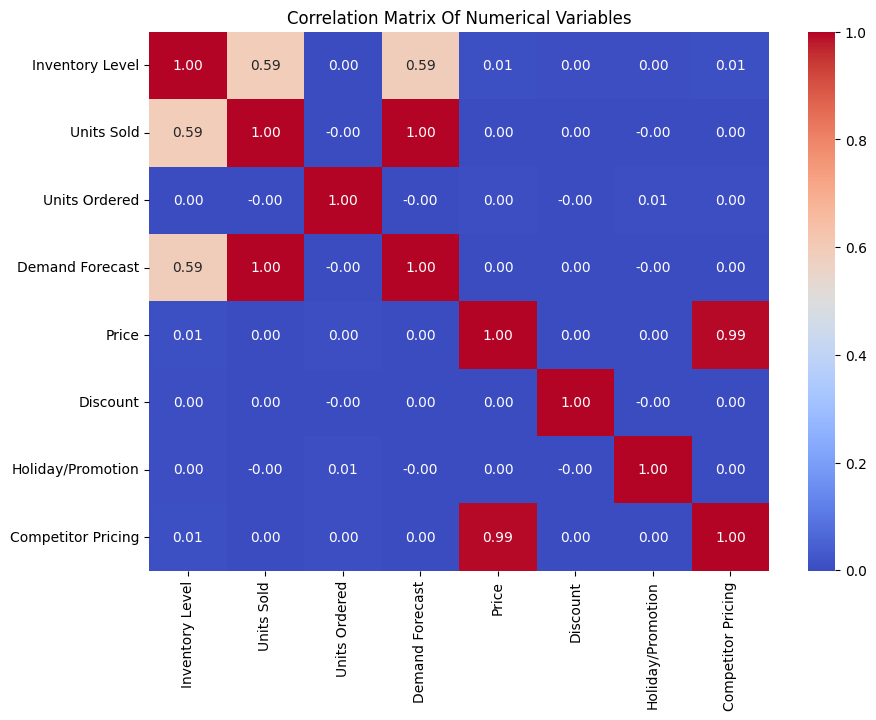

In [ ]:
#Checking numeric correlations:
numeric_columns = df.select_dtypes(include=np.number).columns
correlation = df[numeric_columns].corr()

plt.figure(figsize=(10,7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Of Numerical Variables")                # Correlation only tells us that two variables move together. it doesnt prove one causes the other!
plt.show()

# 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the historical behavior of retail demand and identify patterns that could be useful for forecasting.

## EDA Objectives

The analysis focuses on:

- Overall sales behavior over time
- Short-term demand fluctuations
- Rolling demand patterns
- Demand variability
- Weekday patterns
- Monthly patterns
- Seasonal behavior
- Relationships between sales and business variables

## Daily Sales Aggregation

Because the forecasting objective is initially defined at the overall business level, the individual store and product observations were aggregated by date.

The daily target is calculated as:

**Daily Units Sold = Sum of Units Sold across all stores and products for each date.**

This produces one time-series observation per day.

## Rolling Demand Analysis

Rolling averages were used to smooth short-term fluctuations and reveal the underlying demand level.

The analysis includes:

- 7-day rolling mean
- 30-day rolling mean
- 7-day rolling standard deviation

The rolling statistics help distinguish the underlying demand pattern from daily noise.

## Calendar-Based Analysis

Daily demand was also examined across:

- Days of the week
- Months
- Quarters
- Calendar seasons

These comparisons help identify recurring calendar patterns that may be useful for forecasting.

## Key EDA Questions

The analysis investigates:

1. Is demand trending upward or downward over time?
2. Does demand show recurring weekly behavior?
3. Are some months associated with different demand levels?
4. How volatile is daily demand?
5. Are there unusual peaks or drops that require further investigation?

The findings from EDA are used to guide the subsequent time-series analysis and feature-engineering decisions.

**Creating a working copy:**

**Data Cleaning & Time-Series Preparation:**

The raw dataset is preserved while a working copy is prepared for time-series analysis and forecasting.





In [ ]:
df_clean = df.copy()                     #df_clean -- we can modify this. , df -- preserved
print("Working copy created.")

Working copy created.


In [ ]:
#Convert Date to datetime: (earlier notice that Date was stored as an object, want python to understand that it is actually a date.)

df_clean["Date"] = pd.to_datetime(df_clean["Date"])
#now check:
df_clean["Date"].dtype

dtype('<M8[ns]')

In [ ]:
#Sort dataset chronologically:

df_clean = df_clean.sort_values("Date").reset_index(drop=True)            #Time-series forecasting depends on the correct oder.bcz then historical relationships become difficult to interpret.
df_clean.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S004,P0013,Furniture,East,191,56,65,54.47,61.81,0,Sunny,0,63.92,Autumn
2,2022-01-01,S004,P0012,Electronics,North,349,9,165,0.95,14.25,5,Rainy,1,18.56,Spring
3,2022-01-01,S004,P0011,Electronics,West,205,46,27,46.65,54.84,0,Sunny,1,57.76,Spring
4,2022-01-01,S004,P0010,Groceries,East,447,104,96,115.03,33.48,15,Cloudy,0,37.15,Summer


In [ ]:
#Check chronological order:
is_sorted = df_clean["Date"].is_monotonic_increasing

print("Dates sorted correctly:", is_sorted)

Dates sorted correctly: True


In [ ]:
#check for missing dates again:
unique_dates = df_clean["Date"].drop_duplicates().sort_values()

date_range = pd.date_range(
    start=unique_dates.min(),
    end=unique_dates.max(),
    freq="D"
)

missing_dates = date_range.difference(unique_dates)

print("Expected dates:", len(date_range))
print("Actual dates:", len(unique_dates))
print("Missing dates:", len(missing_dates))

Expected dates: 731
Actual dates: 731
Missing dates: 0


In [ ]:
#Create Calendar features:
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Day"] = df_clean["Date"].dt.day
df_clean["DayOfWeek"] = df_clean["Date"].dt.dayofweek
df_clean["Quarter"] = df_clean["Date"].dt.quarter

In [ ]:
#Create weekday/weekend features:
df_clean["IsWeekend"] = (
    df_clean["DayOfWeek"] >= 5
).astype(int)


df_clean["IsWeekend"]                # 0 = weekday, 1 = weekend (ML algorithms work better with numerical representations.)

,IsWeekend
0,1
1,1
2,1
3,1
4,1
...,...
73095,0
73096,0
73097,0
73098,0


In [ ]:
#Create a readable day name:
df_clean["DayName"] = df_clean["Date"].dt.day_name()
df_clean["DayName"]

,DayName
0,Saturday
1,Saturday
2,Saturday
3,Saturday
4,Saturday
...,...
73095,Monday
73096,Monday
73097,Monday
73098,Monday


**Create a calendar season:**

The existing Seasonality column should not automatically be trusted as a true calendar season. So i'll keep the original column and create a separate calendar-based feature.
Since analyzing a retail dataset in a Northern Hemisphere context, will use:

In [ ]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df_clean["CalendarSeason"] = df_clean["Month"].apply(get_season)

df_clean["CalendarSeason"]

,CalendarSeason
0,Winter
1,Winter
2,Winter
3,Winter
4,Winter
...,...
73095,Winter
73096,Winter
73097,Winter
73098,Winter


In [ ]:
#create a simple date-level identifier:
df_clean["YearMonth"] = df_clean["Date"].dt.to_period("M")

df_clean["YearMonth"]                        #this will be useful later when aggregate sales.this makes monthly analysis easy.

,YearMonth
0,2022-01
1,2022-01
2,2022-01
3,2022-01
4,2022-01
...,...
73095,2024-01
73096,2024-01
73097,2024-01
73098,2024-01


In [ ]:
#Inspect the new dataset:
df_clean.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,Seasonality,Year,Month,Day,DayOfWeek,Quarter,IsWeekend,DayName,CalendarSeason,YearMonth
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,Autumn,2022,1,1,5,1,1,Saturday,Winter,2022-01
1,2022-01-01,S004,P0013,Furniture,East,191,56,65,54.47,61.81,...,Autumn,2022,1,1,5,1,1,Saturday,Winter,2022-01
2,2022-01-01,S004,P0012,Electronics,North,349,9,165,0.95,14.25,...,Spring,2022,1,1,5,1,1,Saturday,Winter,2022-01
3,2022-01-01,S004,P0011,Electronics,West,205,46,27,46.65,54.84,...,Spring,2022,1,1,5,1,1,Saturday,Winter,2022-01
4,2022-01-01,S004,P0010,Groceries,East,447,104,96,115.03,33.48,...,Summer,2022,1,1,5,1,1,Saturday,Winter,2022-01


In [ ]:
df_clean.dtypes

,0
Date,datetime64[ns]
Store ID,object
Product ID,object
Category,object
Region,object
Inventory Level,int64
Units Sold,int64
Units Ordered,int64
Demand Forecast,float64
Price,float64


In [ ]:
df_clean.isnull().sum()

,0
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Demand Forecast,0
Price,0


**Build and explore the retail sales time series:**

**create the daily sales dataset:**

Target Analysis & Time-Series Construction:

The forecasting target is Units Sold, representing observed retail sales.

Because the raw dataset contains multiple store-product observations per day, first aggregate units sold to daily total demand to understand the overall
retail sales pattern.

In [ ]:
daily_sales = (
    df_clean
    .groupby("Date", as_index=False)["Units Sold"]
    .sum()
)

daily_sales.head()

,Date,Units Sold
0,2022-01-01,14484
1,2022-01-02,13415
2,2022-01-03,13681
3,2022-01-04,14084
4,2022-01-05,12572


In [ ]:
daily_sales.shape                    # 731 daily observation -- bcz we combined the 100 store-product observations belonging to each date.

(731, 2)

In [ ]:
# verify that aggregation worked correctly: (lets compare the total sales before and after aggregation)

print("Original total units sold:",
df_clean["Units Sold"].sum())

print("Aggregate total units sold:",
daily_sales["Units Sold"].sum())

Original total units sold: 9975582
Aggregate total units sold: 9975582


In [ ]:
# check the daily time series:
daily_sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        731 non-null    datetime64[ns]
 1   Units Sold  731 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 11.6 KB


In [ ]:
daily_sales.describe()

,Date,Units Sold
count,731,731.000000
mean,2023-01-01 00:00:00.000000256,13646.487004
min,2022-01-01 00:00:00,10642.000000
25%,2022-07-02 12:00:00,12981.000000
50%,2023-01-01 00:00:00,13673.000000
75%,2023-07-02 12:00:00,14323.500000
max,2024-01-01 00:00:00,17239.000000
std,NaN,1031.958966


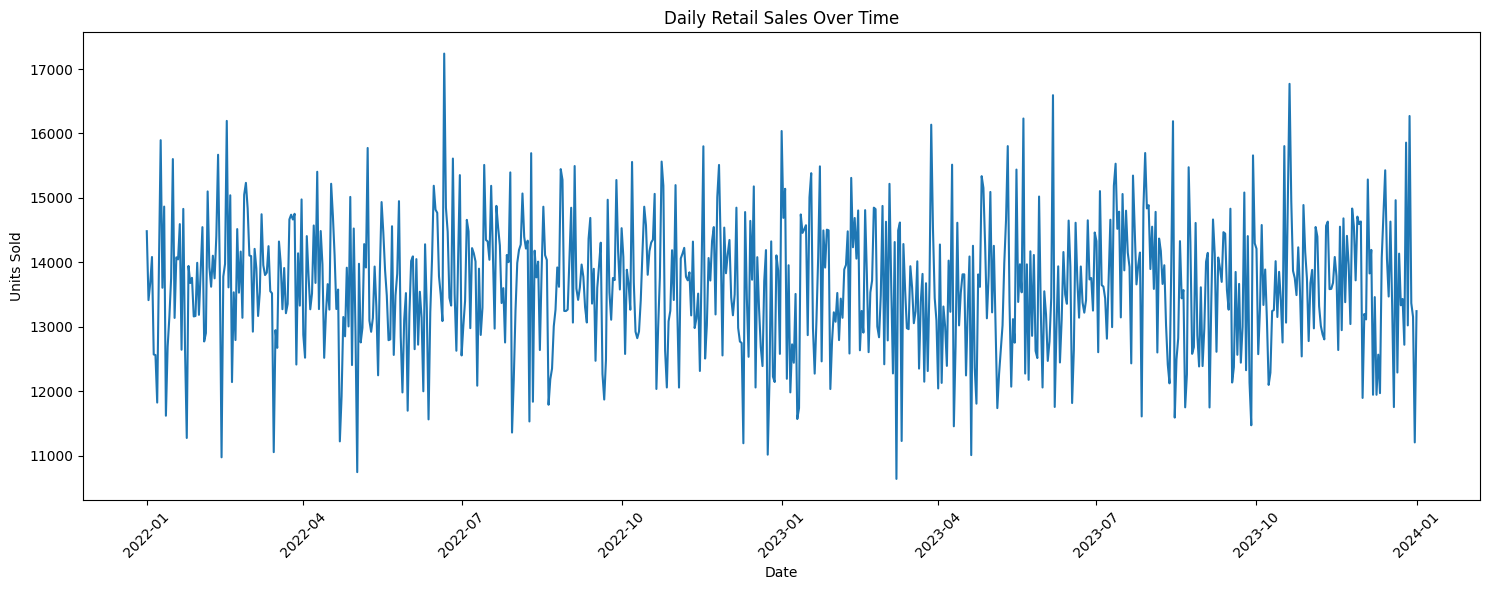

In [ ]:
# Plot daily sales over time:
plt.figure(figsize=(15,6))
plt.plot(
    daily_sales["Date"],
    daily_sales["Units Sold"]
)

plt.title("Daily Retail Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Add a 7-day rolling mean: (daily data can be noisy, a rolling mean smooths short-term fluctuations.)

daily_sales["Rolling_7_Day"] = (
    daily_sales["Units Sold"]
    .rolling(window=7)
    .mean()
)

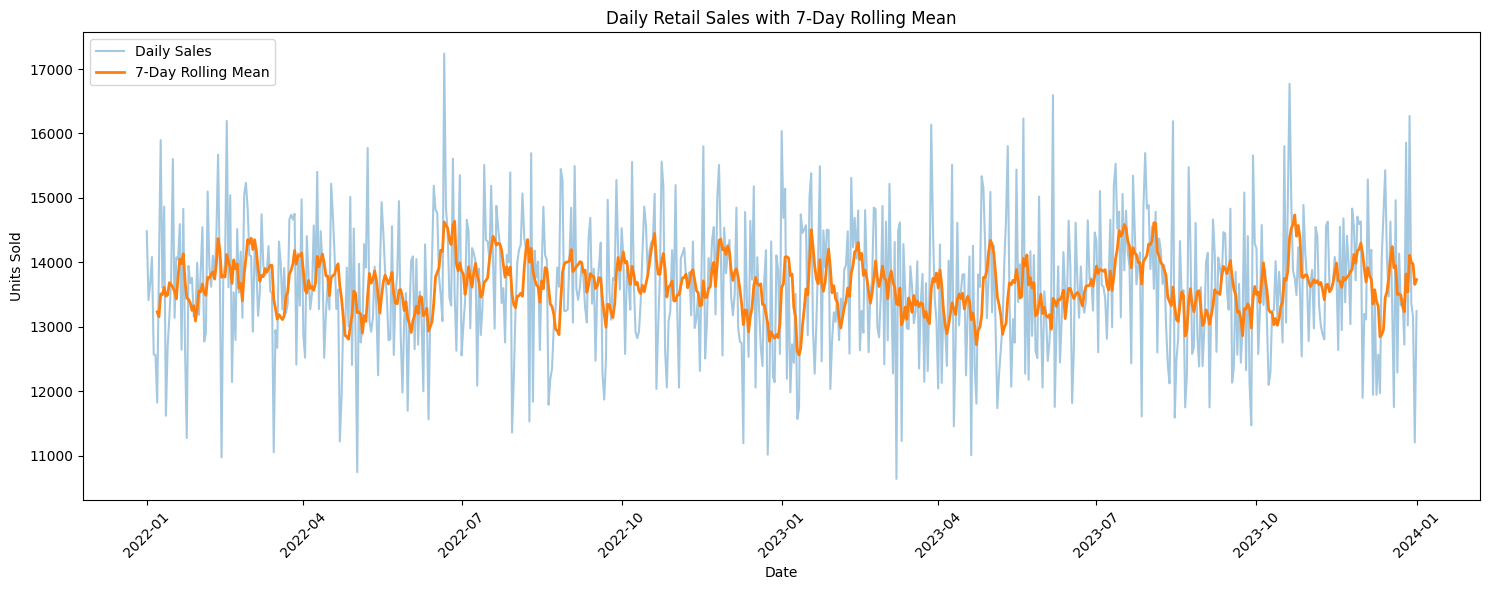

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Units Sold"],
    alpha=0.4,
    label="Daily Sales"
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Rolling_7_Day"],
    linewidth=2,
    label="7-Day Rolling Mean"
)

plt.title("Daily Retail Sales with 7-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Create a 30-day rolling mean: (let's examine longer-term movement):
daily_sales["Rolling_30_Day"] = (
    daily_sales["Units Sold"]
    .rolling(window=30)
    .mean()
)




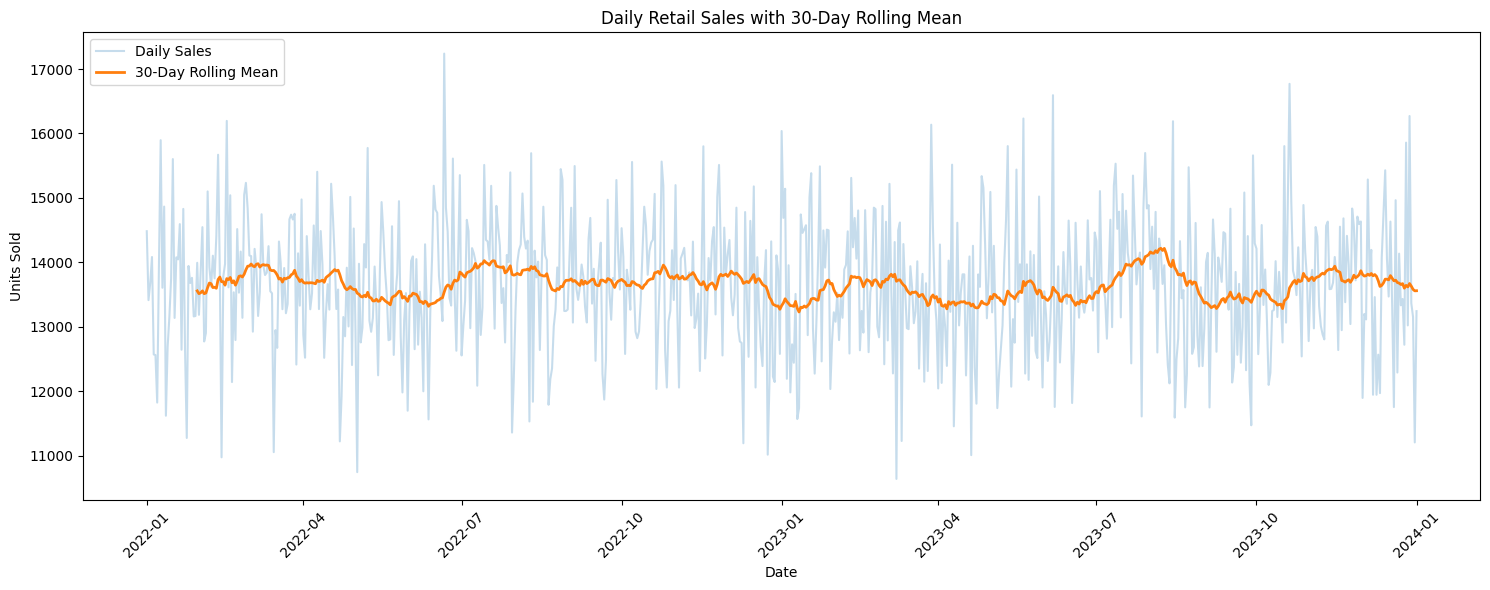

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Date"],
    daily_sales["Units Sold"],
    alpha=0.25,
    label="Daily Sales"
)

plt.plot(
    daily_sales["Date"],
    daily_sales["Rolling_30_Day"],
    linewidth=2,
    label="30-Day Rolling Mean"
)

plt.title("Daily Retail Sales with 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate average sales by weekday :
daily_sales["DayOfWeek"] = daily_sales["Date"].dt.day_name()

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = (
    daily_sales
    .groupby("DayOfWeek")["Units Sold"]
    .mean()
    .reindex(weekday_order)
)

weekday_sales

,Units Sold
DayOfWeek,
Monday,13509.466667
Tuesday,13730.769231
Wednesday,13661.509615
Thursday,13728.192308
Friday,13685.144231
Saturday,13531.447619
Sunday,13680.971429


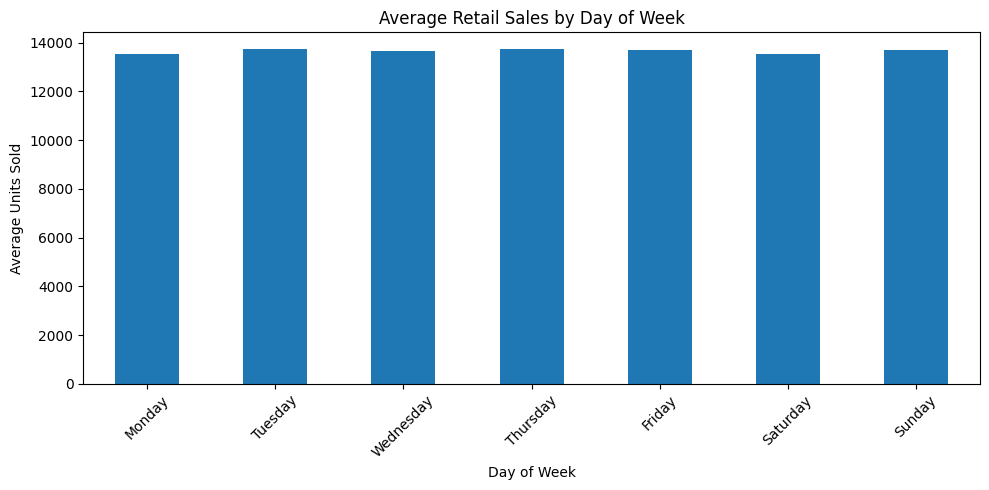

In [ ]:
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Retail Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate average sales by month :
daily_sales["Month"] = daily_sales["Date"].dt.month

monthly_sales = (
    daily_sales
    .groupby("Month")["Units Sold"]
    .mean()
)

monthly_sales

,Units Sold
Month,
1,13596.666667
2,13861.071429
3,13590.241935
4,13474.283333
5,13443.096774
6,13685.833333
7,13944.306452
8,13571.241935
9,13616.183333


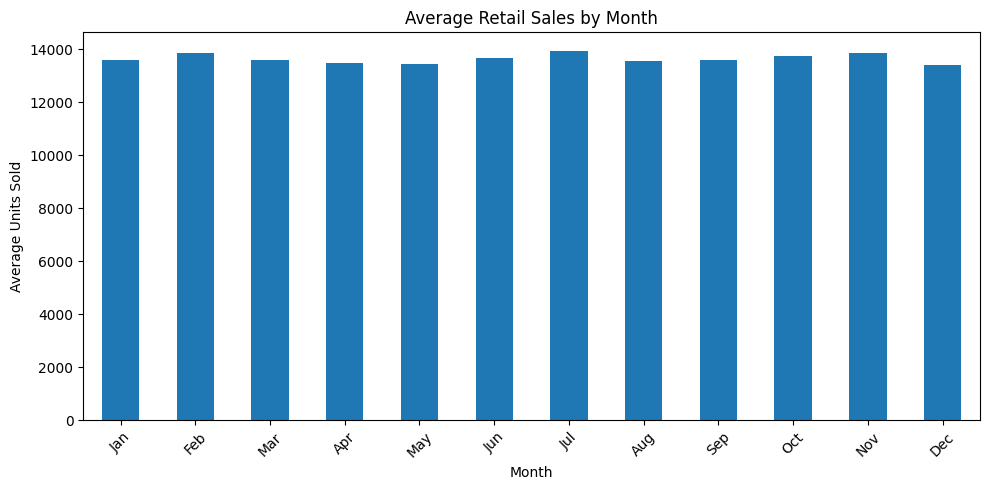

In [ ]:
plt.figure(figsize=(10, 5))

monthly_sales.plot(kind="bar")

plt.title("Average Retail Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(range(12), [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
], rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Examine monthly total sales:
monthly_total_sales = (
    daily_sales
    .groupby(daily_sales["Date"].dt.to_period("M"))["Units Sold"]
    .sum()
)

monthly_total_sales.head()

,Units Sold
Date,
2022-01,419938
2022-02,391052
2022-03,426073
2022-04,407380
2022-05,414799


In [ ]:
monthly_total_sales.tail()

,Units Sold
Date,
2023-09,405361
2023-10,425646
2023-11,416126
2023-12,418672
2024-01,13244


In [ ]:
# Checking rolling variability:
# Calculate a 7-day rolling standard deviation:

daily_sales["Rolling_7_Day_Std"] = (
    daily_sales["Units Sold"]
    .rolling(window=7)
    .std()
)

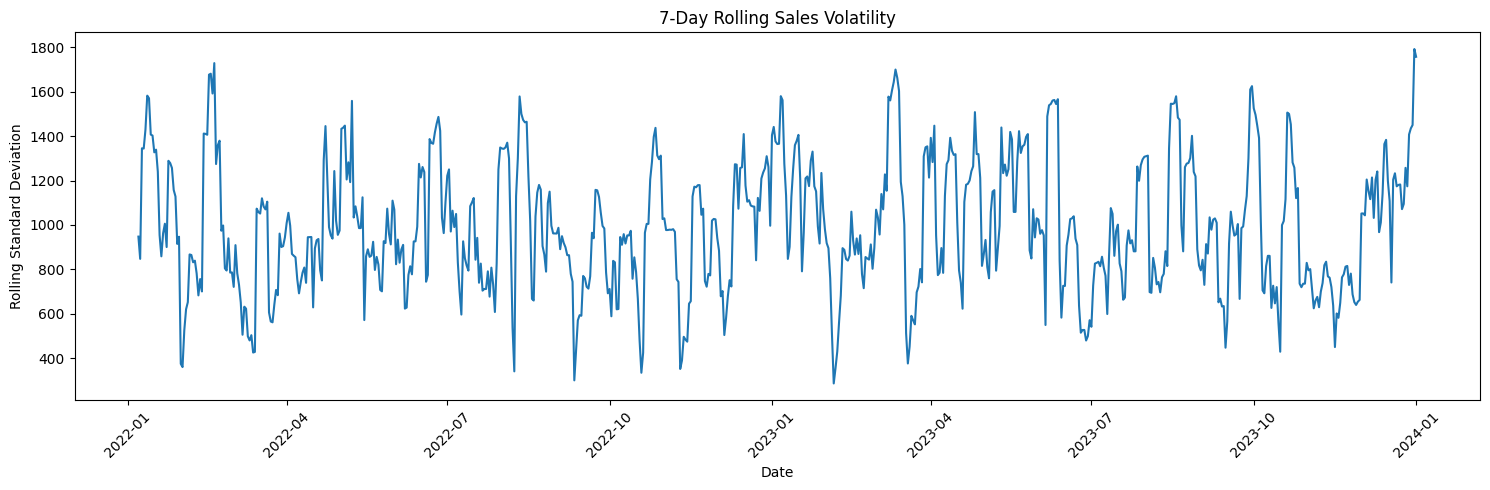

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_sales["Date"],
    daily_sales["Rolling_7_Day_Std"]
)

plt.title("7-Day Rolling Sales Volatility")
plt.xlabel("Date")
plt.ylabel("Rolling Standard Deviation")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

It tells us whether sales are relatively:

Stable → low variation

Volatile → high variation

This becomes useful for inventory planning.

A store with highly volatile demand may need a different inventory strategy from a store with stable demand.

#Trend, Seasonality & Time-Series Decomposition :
This step answers:

          "What components are driving the movement of retail sales over time?"


Trend = the long-term direction of the series.

Seasonality = a pattern that repeats at a known regular interval.

Residual = unexplained/random component.

In [ ]:
# Seasonal Decomposition:
#First, make sure 'Date' is our index. Create a new copy, don't accidentally modify our existing data:

ts = daily_sales.set_index("Date")["Units Sold"].copy()
ts.head()

,Units Sold
Date,
2022-01-01,14484
2022-01-02,13415
2022-01-03,13681
2022-01-04,14084
2022-01-05,12572


In [ ]:
# Import Decomposition:
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
# now perform decomposition:
# Import decision:

period = 7               #(for investigating weekly seasonality in daily retail sales.)

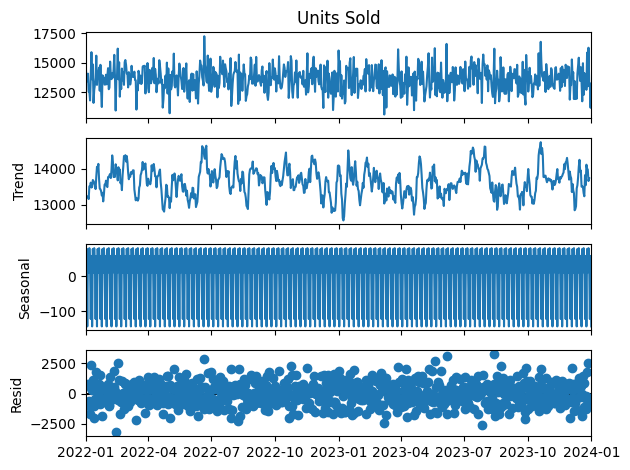

In [ ]:
decomposition = seasonal_decompose(
    ts,
    model="additive",                # additive -- sales = trend + seasonality + residual
    period=7                         #multiplicative decomposition -- sales = trend * seasonality * residual
)

decomposition.plot()
plt.tight_layout()
plt.show()

In [ ]:
# Examine weekly seasonality more carefully:

weekday_sales = (
    daily_sales
    .groupby(daily_sales["Date"].dt.day_name())["Units Sold"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekday_sales

,Units Sold
Date,
Monday,13509.466667
Tuesday,13730.769231
Wednesday,13661.509615
Thursday,13728.192308
Friday,13685.144231
Saturday,13531.447619
Sunday,13680.971429


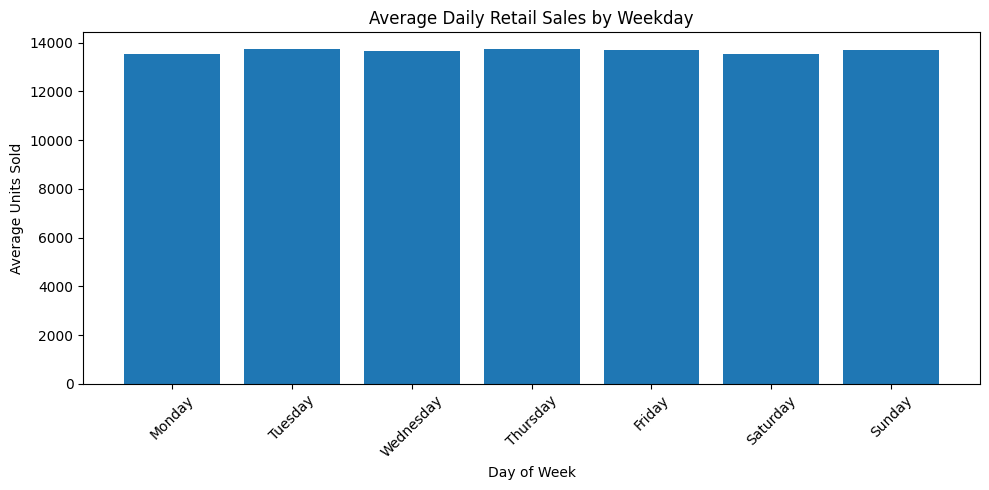

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    weekday_sales.index,
    weekday_sales.values
)

plt.title("Average Daily Retail Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Examine monthly seasonality:
monthly_avg = (
    daily_sales
    .groupby(daily_sales["Date"].dt.month)["Units Sold"]
    .mean()
)

monthly_avg

,Units Sold
Date,
1,13596.666667
2,13861.071429
3,13590.241935
4,13474.283333
5,13443.096774
6,13685.833333
7,13944.306452
8,13571.241935
9,13616.183333


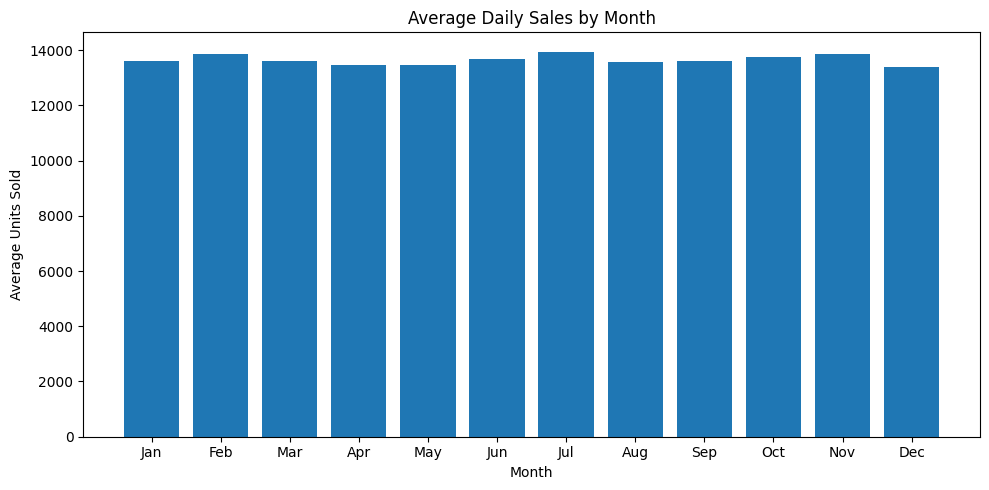

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_avg.index,
    monthly_avg.values
)

plt.title("Average Daily Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.tight_layout()
plt.show()

Next examine autocorrelation function:
    ACF tells us whether today's sales are related to sales from previous days.
For example:

Lag 1 → Is today's sales related to yesterday's sales?

Lag 2 → Is today's sales related to sales 2 days ago?

Lag 7 → Is today's sales related to sales 7 days ago?

Lag 14 → Is today's sales related to sales 14 days ago?

**So, ACF helps us discover repeating patterns and dependencies in time-series data.**

In [ ]:
# Calculate autocorrelation:
from statsmodels.tsa.stattools import acf

acf_values = acf(
    ts,
    nlags=30,
    fft=True
)

acf_values[:10]

array([ 1.        ,  0.02290149, -0.00958868, -0.03481099, -0.01408512,
        0.01280666, -0.0033186 , -0.00975551, -0.02089459, -0.01244871])

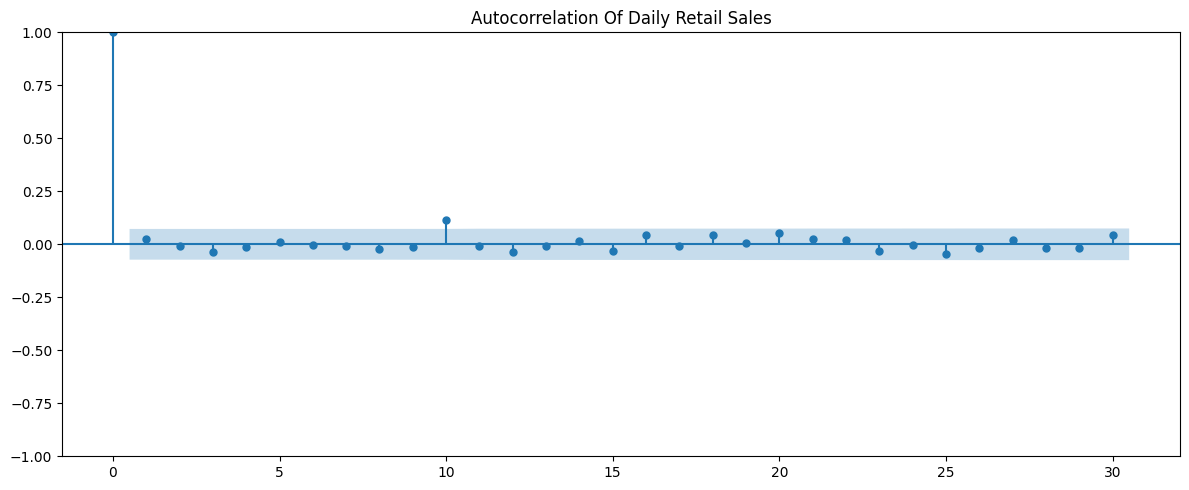

In [ ]:
# Plot the ACF :
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12,5))
plot_acf(
    ts,
    lags=30,
    ax=plt.gca()
)

plt.title("Autocorrelation Of Daily Retail Sales")
plt.tight_layout()
plt.show()


"The ACF of our daily aggregated retail sales showed mostly weak autocorrelation across the examined lags, with no strong repeating weekly pattern evident from the ACF plot."

**PACF (Partial Autocorrelation Function):**
       PACF measures the direct relationship between today's sales and a
       previous lag after accounting for the effects of the intermediate lags.
       this is particularly useful when choosing AR terms in ARIMA.

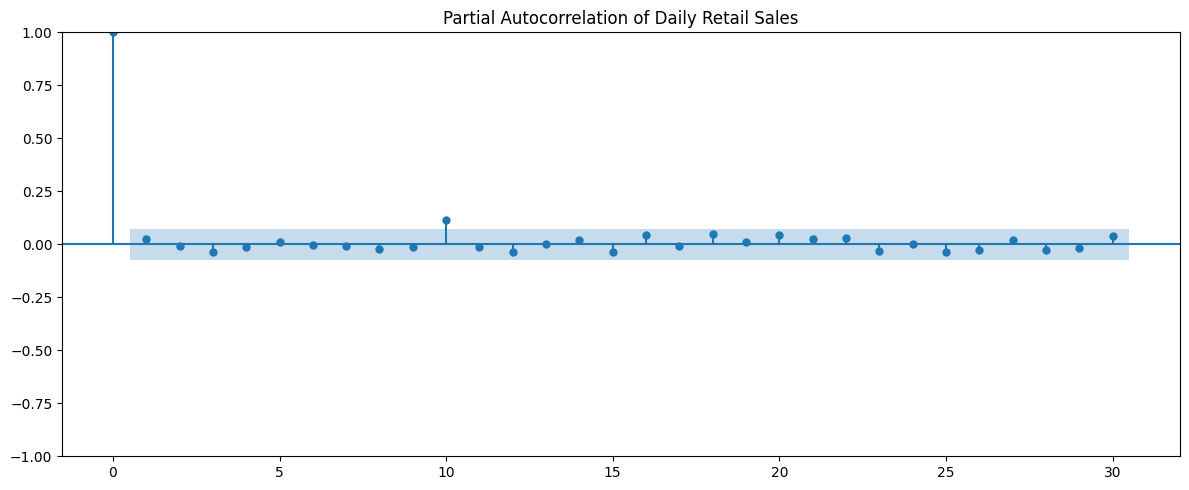

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))

plot_pacf(
    ts,
    lags=30,
    method="ywm",
    ax=plt.gca()
)

plt.title("Partial Autocorrelation of Daily Retail Sales")
plt.tight_layout()
plt.show()

    ACF helps to identify MA (Moving Average).it can help us choose the MA order(q).

    In ARIMA, MA uses previous forecast errors(residuals) to help predict the current value.

    PACF helps identify AR (Auto Regressive). it can help us choose the AR oder(p).

    In ARIMA, AR uses previous actual values of the series to predict the current value.

ARIMA-type models generally work best when the underlying series is stationary or has been transformed to become stationary.

stationary means roughly:

mean -- relatively stable

variance -- relatively stable

structure -- relatively stable over time

In [ ]:
# Augmented Dickey-Fuller test: (ADF test): It is a statistical test used to check whether a time series is stationary (reasonably stable over time) or non-stationary.
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(ts)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("Result: The series appears stationary.")
else:
    print("Result: The series appears non-stationary.")

ADF Statistic: -26.379506701264116
p-value: 0.0
Result: The series appears stationary.


/tmp/ipykernel_2437/487957875.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ts)


**Remove the incomplete final date :**
the dataset has: 2022-01-01 -> 2024-01-01

But 2024-01-01 contains only one day of observations, so shouldn't treat it as a normal complete month/forecasting period.

let's first create a modeling series ending at 2023-12-31.

In [ ]:
#Remove the incomplete final date from the modeling data:

daily_sales_model = daily_sales[daily_sales["Date"] < "2024-01-01"].copy()

print("Start date:", daily_sales_model["Date"].min())
print("End date:", daily_sales_model["Date"].max())
print("Number of days:", len(daily_sales_model))

Start date: 2022-01-01 00:00:00
End date: 2023-12-31 00:00:00
Number of days: 730


In [ ]:
#Create train/test split :

#Calculate the split point:
split_index = int(len(daily_sales_model)*0.80)

#Time-based split:
train = daily_sales_model.iloc[:split_index].copy()
test = daily_sales_model.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train["Date"].min(), "to", train["Date"].max())

print("\nTesting period:")
print(test["Date"].min(), "to", test["Date"].max())


Training observations: 584
Testing observations: 146

Training period:
2022-01-01 00:00:00 to 2023-08-07 00:00:00

Testing period:
2023-08-08 00:00:00 to 2023-12-31 00:00:00


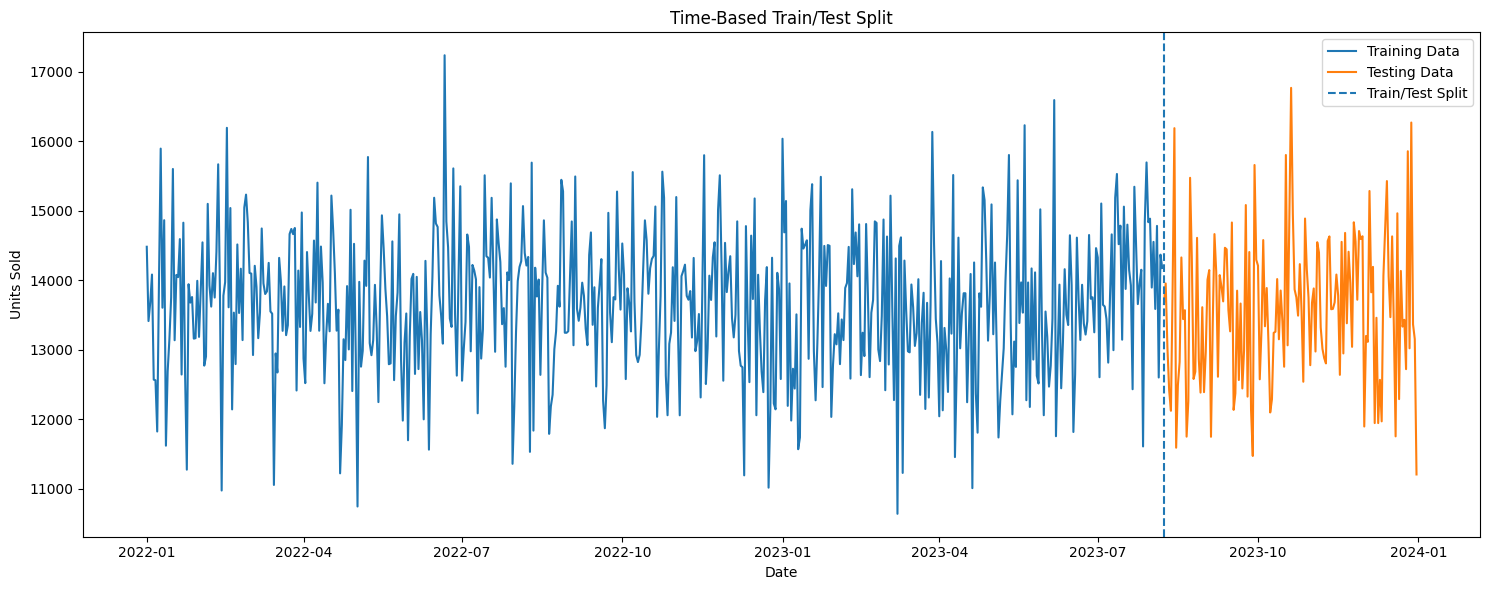

In [ ]:
#Visualize the split:

plt.figure(figsize=(15, 6))

plt.plot(
    train["Date"],
    train["Units Sold"],
    label="Training Data"
)

plt.plot(
    test["Date"],
    test["Units Sold"],
    label="Testing Data"
)

plt.axvline(
    test["Date"].iloc[0],
    linestyle="--",
    label="Train/Test Split"
)

plt.title("Time-Based Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()

plt.tight_layout()
plt.show()


# Build a Naive Baseline Forecast:
(Purpose = Establish a performance benchmark.)

    Naive Forecast: "Tomorrow's sales will be the same as today's sales."

In [ ]:
# Create the Naive Forecast:

last_train_value = train["Units Sold"].iloc[-1]

naive_forecast = np.repeat(last_train_value, len(test))

print("Last training value:", last_train_value)
print("Number of forecasted days:", len(naive_forecast))

Last training value: 14178
Number of forecasted days: 146


In [ ]:
# Put actual and predicted values together:

naive_results = pd.DataFrame({
    "Date": test["Date"].values,
    "Actual": test["Units Sold"].values,
    "Naive Forecast": naive_forecast
})

naive_results.head()                           #Naive Forecast stays constant.that's expected!

,Date,Actual,Naive Forecast
0,2023-08-08,13666,14178
1,2023-08-09,13956,14178
2,2023-08-10,13028,14178
3,2023-08-11,12414,14178
4,2023-08-12,12124,14178


In [ ]:
# Calculate MAE and RMSE :

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_naive = mean_absolute_error(
    naive_results["Actual"],
    naive_results["Naive Forecast"]
)

rmse_naive = np.sqrt(
    mean_squared_error(
        naive_results["Actual"],
        naive_results["Naive Forecast"]
    )
)

print("Naive Baseline MAE:", mae_naive)
print("Naive Baseline RMSE:", rmse_naive)

Naive Baseline MAE: 975.2534246575342
Naive Baseline RMSE: 1204.4176419184432


MAE: 975 means the forecast is off by about 975 units on average. (lower = better).

RMSE: 1204 its also measures prediction error,but it penalizes large errors more heavily. (lower = better).

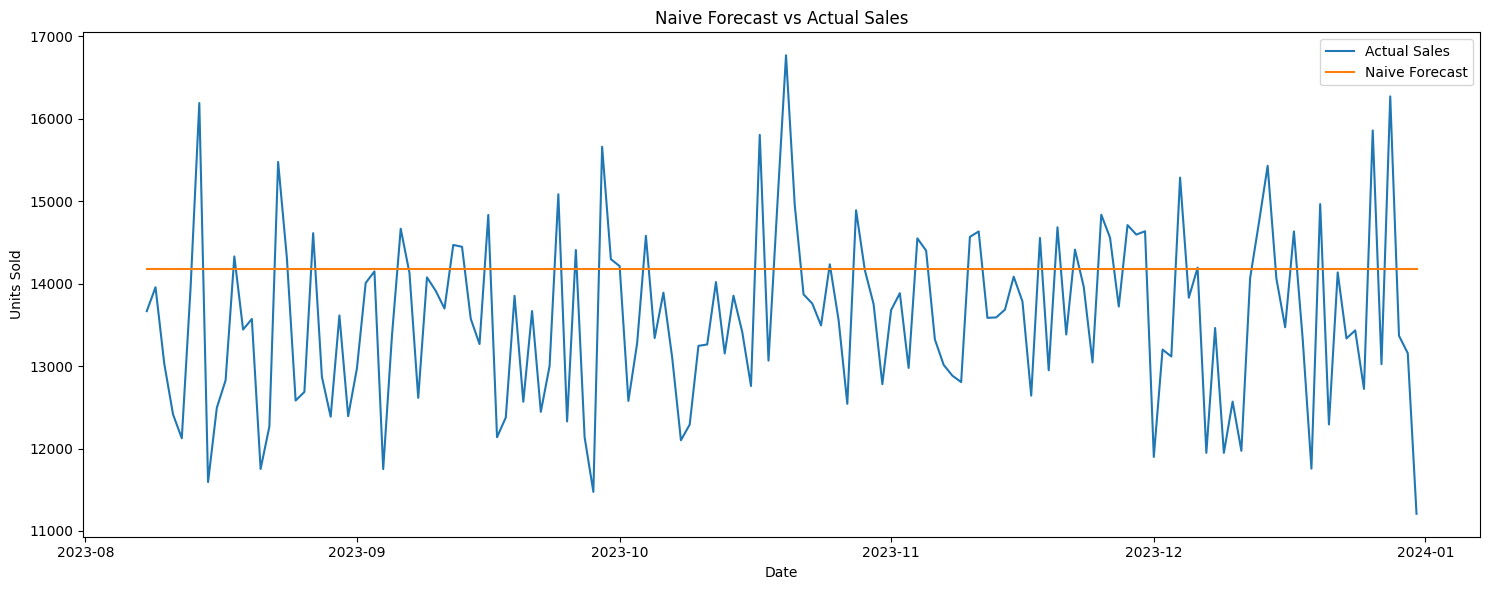

In [ ]:
# Compare Forecast with Actual Sales:
plt.figure(figsize=(15, 6))

plt.plot(
    test["Date"],
    test["Units Sold"],
    label="Actual Sales"
)

plt.plot(
    test["Date"],
    naive_forecast,
    label="Naive Forecast"
)

plt.title("Naive Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()

plt.tight_layout()
plt.show()

“Established a naive forecasting baseline and evaluated models using MAE and RMSE to determine whether advanced forecasting approaches provide meaningful improvement.”

# ARIMA : AutoRegressive Integrated Moving Average
    It uses patterns in previous observations and previous forecasting errors to predict future values.

    It has 3 important parameters:  ARIMA(p, d, q)


| Parameter | Meaning | Simple explanation                         |
| --------- | ------- | ------------------------------------------ |
| `p`       | AR      | Uses previous sales values                 |
| `d`       | I       | Differencing to make the series stationary |
| `q`       | MA      | Uses previous forecasting errors           |




For example:

ARIMA(1, 0, 1)

means:

p = 1 → use 1 previous sales value

d = 0 → no differencing

q = 1 → use 1 previous error



In [ ]:
# Prepare the training and testing series:

train_ts = train.set_index("Date")["Units Sold"]
test_ts = test.set_index("Date")["Units Sold"]

print("Training observations:", len(train_ts))
print("Testing observations:", len(test_ts))

print("\nTraining period:")
print(train_ts.index.min(), "to", train_ts.index.max())

print("\nTesting period:")
print(test_ts.index.min(), "to", test_ts.index.max())

Training observations: 584
Testing observations: 146

Training period:
2022-01-01 00:00:00 to 2023-08-07 00:00:00

Testing period:
2023-08-08 00:00:00 to 2023-12-31 00:00:00


ARIMA must never learn from the test data.

**Build ARIMA(1,0,0) :**
let's start with the simplest ARIMA model containing an AR component.

   ARIMA(1,0,0)
       


        │ │ └── q = 0 → no MA component

        │ └──── d = 0 → no differencing

        └────── p = 1 → use 1 previous value



So, conceptually:

ARIMA(1,0,0) tries to predict today's sales partly from the previous day's sales.


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

arima_100 = ARIMA(
    train_ts,
    order=(1, 0, 0)
)

arima_100_fit = arima_100.fit()

print(arima_100_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Units Sold   No. Observations:                  584
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -4877.726
Date:                Sat, 10 Oct 2026   AIC                           9761.451
Time:                        14:59:34   BIC                           9774.561
Sample:                    01-01-2022   HQIC                          9766.561
                         - 08-07-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.366e+04     43.784    312.010      0.000    1.36e+04    1.37e+04
ar.L1          0.0282      0.042      0.669      0.503      -0.054       0.111
sigma2      1.053e+06   6.08e+04     17.321      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [ ]:
# Generate the ARIMA forecast

arima_100_forecast = arima_100_fit.forecast(
    steps=len(test_ts)
)

print("Number of forecasted days:", len(arima_100_forecast))

print("\nFirst 5 forecasts:")
print(arima_100_forecast.head())

Number of forecasted days: 146

First 5 forecasts:
2023-08-08    13675.563015
2023-08-09    13661.382724
2023-08-10    13660.982514
2023-08-11    13660.971219
2023-08-12    13660.970900
Freq: D, Name: predicted_mean, dtype: float64


In [ ]:
# Evaluate ARIMA(1,0,0)

mae_arima_100 = mean_absolute_error(
    test_ts,
    arima_100_forecast
)

rmse_arima_100 = np.sqrt(
    mean_squared_error(
        test_ts,
        arima_100_forecast
    )
)

print("ARIMA(1,0,0) MAE:", mae_arima_100)
print("ARIMA(1,0,0) RMSE:", rmse_arima_100)

print("\nNaive Baseline MAE:", mae_naive)
print("Naive Baseline RMSE:", rmse_naive)

ARIMA(1,0,0) MAE: 845.7188998288881
ARIMA(1,0,0) RMSE: 1054.1662082972916

Naive Baseline MAE: 975.2534246575342
Naive Baseline RMSE: 1204.4176419184432


So the first statistical model is already providing useful improvement over the simple baseline.

In [ ]:
# Test more ARIMA configurations

arima_orders = [
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 0),
    (0, 0, 2)
]

arima_results = []

for order in arima_orders:
    model = ARIMA(train_ts, order=order)
    fitted_model = model.fit()

    forecast = fitted_model.forecast(steps=len(test_ts))

    mae = mean_absolute_error(test_ts, forecast)
    rmse = np.sqrt(mean_squared_error(test_ts, forecast))

    arima_results.append({
        "Model": f"ARIMA{order}",
        "MAE": mae,
        "RMSE": rmse
    })

arima_results_df = pd.DataFrame(arima_results)

arima_results_df

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dat

,Model,MAE,RMSE
0,"ARIMA(0, 0, 1)",845.718379,1054.166918
1,"ARIMA(1, 0, 1)",845.715018,1054.168133
2,"ARIMA(2, 0, 0)",845.711468,1054.171651
3,"ARIMA(0, 0, 2)",845.709740,1054.170487


All of these simple ARIMA models perform almost identically.



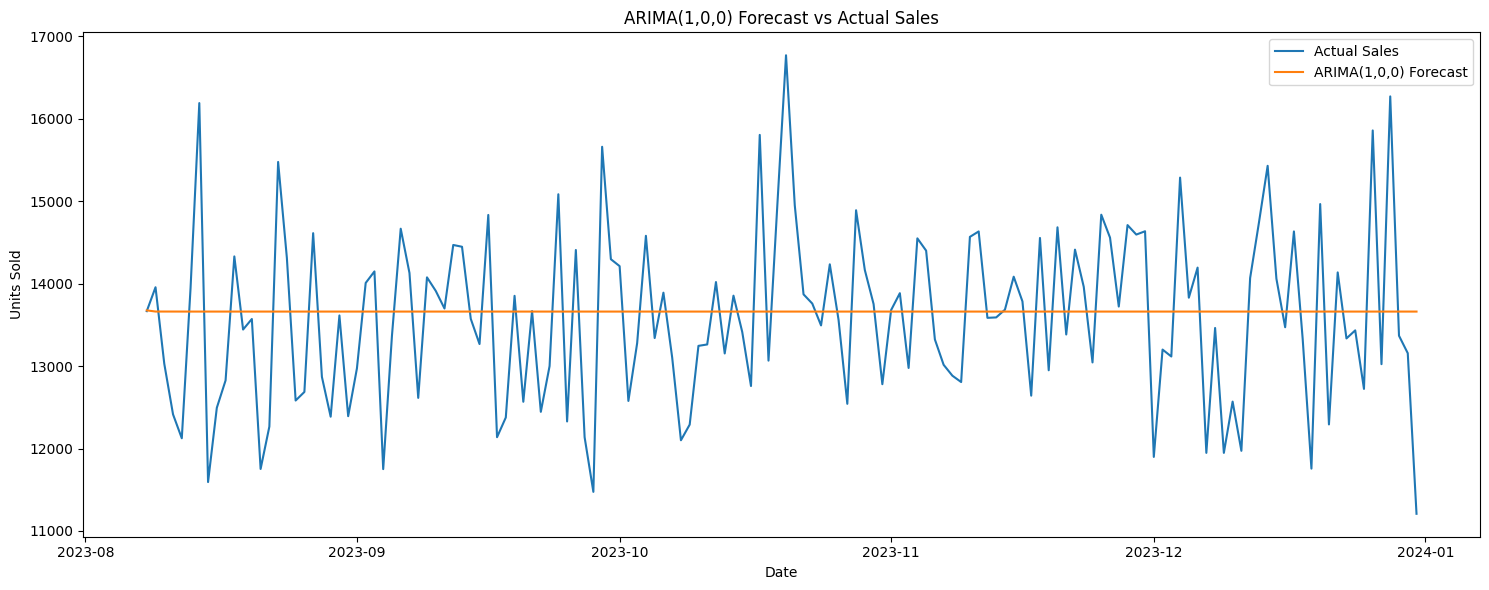

In [ ]:
# Plot ARIMA vs Actual

plt.figure(figsize=(15, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual Sales"
)

plt.plot(
    test_ts.index,
    arima_100_forecast.values,
    label="ARIMA(1,0,0) Forecast"
)

plt.title("ARIMA(1,0,0) Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()

plt.tight_layout()
plt.show()

So ARIMA(1,0,0) essentially learned:

"Yesterday's sales don't provide much information about the next day's total sales."

Consequently, when forecasting many days into the future, the predictions quickly move toward the estimated average level.

So despite the flat-looking forecast, ARIMA still performed better than the naive baseline on unseen test data.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "ARIMA(1,0,0)"
    ],
    "MAE": [
        mae_naive,
        mae_arima_100
    ],
    "RMSE": [
        rmse_naive,
        rmse_arima_100
    ]
})

model_comparison

,Model,MAE,RMSE
0,Naive Baseline,975.253425,1204.417642
1,"ARIMA(1,0,0)",845.718900,1054.166208


If the seasonal naive baseline shows useful information, will try a much simpler SARIMA.

If it doesn't, then have evidence that weekly SARIMA may not add much value.

In [ ]:
# Seasonal Naive Baseline

seasonal_naive_forecast = train_ts.iloc[-7:].tolist()

seasonal_naive_forecast = np.tile(
    seasonal_naive_forecast,
    int(np.ceil(len(test_ts) / 7))
)[:len(test_ts)]

mae_seasonal_naive = mean_absolute_error(
    test_ts,
    seasonal_naive_forecast
)

rmse_seasonal_naive = np.sqrt(
    mean_squared_error(
        test_ts,
        seasonal_naive_forecast
    )
)

print("Seasonal Naive MAE:", mae_seasonal_naive)
print("Seasonal Naive RMSE:", rmse_seasonal_naive)

print("\nRegular Naive MAE:", mae_naive)
print("Regular Naive RMSE:", rmse_naive)

Seasonal Naive MAE: 1095.9041095890411
Seasonal Naive RMSE: 1343.7901723845357

Regular Naive MAE: 975.2534246575342
Regular Naive RMSE: 1204.4176419184432


This agrees with what saw earlier in ACF/PACF analysis: there wasn't strong evidence of a weekly pattern. and now it also have evidence that a simple 7-day seasonal approach isn't useful.

"A 7-day seasonal-naive benchmark was evaluated but performed worse than the regular naive baseline, providing limited evidence that weekly seasonality improves forecasting at the aggregated daily level."

# Prophet Forecasting:
    "What underlying trend and recurring time patterns can explain the sales over time?"

In [ ]:
!pip install prophet -q

In [ ]:
from prophet import Prophet

print("Prophet imported successfully!")

Prophet imported successfully!


In [ ]:
# Create a separate Dataframe for prohet ds and y :

prophet_train = train[["Date", "Units Sold"]].copy()

prophet_train = prophet_train.rename(
    columns={
        "Date": "ds",
        "Units Sold": "y"
    }
)

print(prophet_train.head())
print("\nShape:", prophet_train.shape)
print("\nDate range:")
print(prophet_train["ds"].min(), "to", prophet_train["ds"].max())

          ds      y
0 2022-01-01  14484
1 2022-01-02  13415
2 2022-01-03  13681
3 2022-01-04  14084
4 2022-01-05  12572

Shape: (584, 2)

Date range:
2022-01-01 00:00:00 to 2023-08-07 00:00:00


don't want to modify train itself. simply creating a Prophet-specific version:

train
  ↓

prophet_train
  ↓

ds = Date

y  = Units Sold

This is a good practice when working with different forecasting libraries.

In [ ]:
# Fit the Prophet model

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Prophet model fitted successfully!")

Prophet model fitted successfully!


In [ ]:
# Generate Prophet's test-period forecast
#Now let's forecast the 146 days in test set :

prophet_future = prophet_model.make_future_dataframe(
    periods=len(test),                                      # periods=len(test) -- asks Prophet for 146 future days
    freq="D"                                                # freq="D" -- daily forecast
)

prophet_forecast = prophet_model.predict(prophet_future)

print(prophet_forecast[["ds", "yhat"]].tail(len(test)))        # yhat -- Prophet's predicted sales

            ds          yhat
584 2023-08-08  13811.577526
585 2023-08-09  13611.619343
586 2023-08-10  13716.606190
587 2023-08-11  13671.326899
588 2023-08-12  13378.490429
..         ...           ...
725 2023-12-27  13134.793209
726 2023-12-28  13294.634368
727 2023-12-29  13303.347108
728 2023-12-30  13062.588863
729 2023-12-31  13313.008361

[146 rows x 2 columns]


In [ ]:
# Evaluate Prophet

prophet_test_forecast = prophet_forecast[
    prophet_forecast["ds"].isin(test_ts.index)
]["yhat"].values

mae_prophet = mean_absolute_error(
    test_ts.values,
    prophet_test_forecast
)

rmse_prophet = np.sqrt(
    mean_squared_error(
        test_ts.values,
        prophet_test_forecast
    )
)

print("Prophet MAE:", mae_prophet)
print("Prophet RMSE:", rmse_prophet)

Prophet MAE: 850.9036325504604
Prophet RMSE: 1065.2344440082388


In [ ]:
# Prophet without yearly seasonality

prophet_model_no_yearly = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model_no_yearly.fit(prophet_train)

print("Prophet model without yearly seasonality fitted successfully!")

Prophet model without yearly seasonality fitted successfully!


In [ ]:
# Forecast with yearly seasonality OFF

prophet_future_no_yearly = prophet_model_no_yearly.make_future_dataframe(
    periods=len(test),
    freq="D"
)

prophet_forecast_no_yearly = prophet_model_no_yearly.predict(
    prophet_future_no_yearly
)

prophet_test_forecast_no_yearly = prophet_forecast_no_yearly[
    prophet_forecast_no_yearly["ds"].isin(test_ts.index)
]["yhat"].values

print("Number of test predictions:", len(prophet_test_forecast_no_yearly))
print("\nFirst 5 predictions:")
print(prophet_test_forecast_no_yearly[:5])

Number of test predictions: 146

First 5 predictions:
[13870.6844136  13710.2747386  13853.36904257 13842.37422117
 13575.6455999 ]


In [ ]:
# Evaluate Prophet without yearly seasonality

mae_prophet_no_yearly = mean_absolute_error(
    test_ts.values,
    prophet_test_forecast_no_yearly
)

rmse_prophet_no_yearly = np.sqrt(
    mean_squared_error(
        test_ts.values,
        prophet_test_forecast_no_yearly
    )
)

print("Prophet (No Yearly Seasonality) MAE:", mae_prophet_no_yearly)
print("Prophet (No Yearly Seasonality) RMSE:", rmse_prophet_no_yearly)

Prophet (No Yearly Seasonality) MAE: 875.3634204644993
Prophet (No Yearly Seasonality) RMSE: 1085.7772850932515


1. Yearly seasonality helped Prophet on this test set. So removing yearly seasonality increased the MAE and RMSE.

2. However, Prophet's improvement over the Naive baseline is clear, while its difference from ARIMA is small.

3. "Prophet's yearly seasonality was evaluated despite limited historical coverage. It produced slightly lower test error than the version without yearly seasonality, although the improvement should be interpreted cautiously because the training period contains less than two complete years."

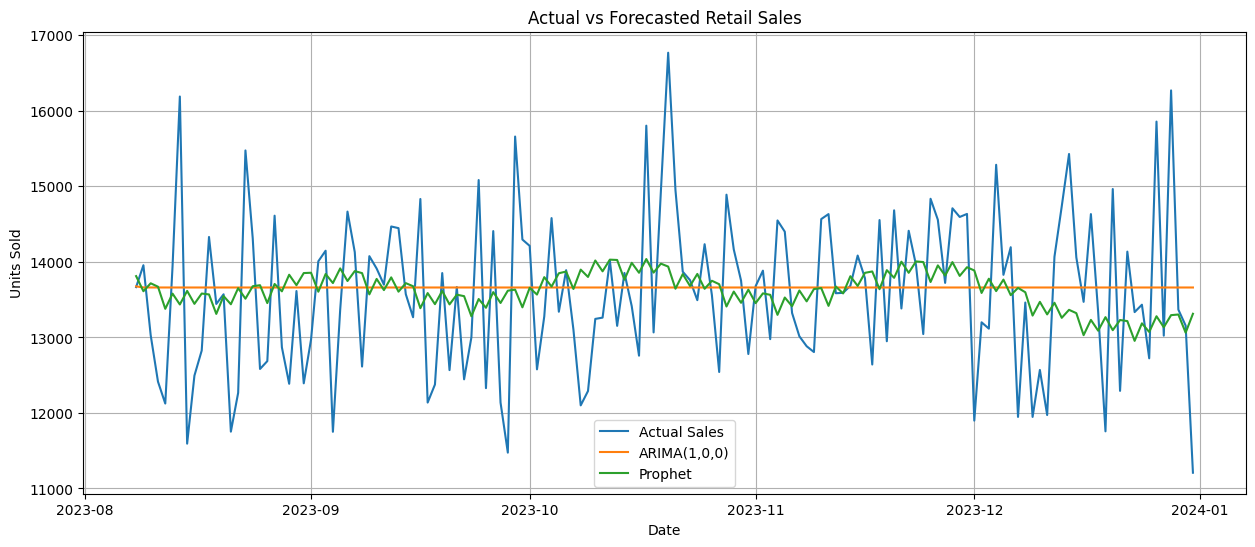

In [ ]:
# Actual vs ARIMA vs Prophet : (because metrics tell us how much error the models have, while the graph shows how the forecasts behave.)

plt.figure(figsize=(15, 6))

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Actual Sales"
)

plt.plot(
    test_ts.index,
    arima_100_forecast.values,
    label="ARIMA(1,0,0)"
)

plt.plot(
    test_ts.index,
    prophet_test_forecast,
    label="Prophet"
)

plt.title("Actual vs Forecasted Retail Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)

plt.show()


**"ARIMA and Prophet substantially improved upon the naive baseline, but both produced relatively smooth forecasts and struggled to capture short-term sales volatility. This motivated the development of feature-based machine-learning forecasting models incorporating historical sales patterns and business-related predictors."**



# Feature Engineering for ML Forecasting

the ARIMA and Prophet models mainly used the time series itself. Now create features that help a machine-learning model understand recent sales patterns and calendar effects.


First: an important forecasting concept

Must avoid data leakage.

So our lag and rolling features must always use past information only.


**Create lag features**

Start with four important historical-sales features:

Feature & its Meaning :

Lag_1	                                      
Sales yesterday

Lag_7	                  
Sales 7 days ago

Lag_14	                
Sales 14 days ago

Lag_28	               
Sales 28 days ago


These can help the ML model recognize short-term and recurring patterns.

In [ ]:
ml_data = daily_sales_model.copy()

ml_data["Lag_1"] = ml_data["Units Sold"].shift(1)
ml_data["Lag_7"] = ml_data["Units Sold"].shift(7)
ml_data["Lag_14"] = ml_data["Units Sold"].shift(14)
ml_data["Lag_28"] = ml_data["Units Sold"].shift(28)

print(ml_data.head(35))

         Date  Units Sold  Rolling_7_Day  Rolling_30_Day  DayOfWeek  Month  \
0  2022-01-01       14484            NaN             NaN   Saturday      1   
1  2022-01-02       13415            NaN             NaN     Sunday      1   
2  2022-01-03       13681            NaN             NaN     Monday      1   
3  2022-01-04       14084            NaN             NaN    Tuesday      1   
4  2022-01-05       12572            NaN             NaN  Wednesday      1   
5  2022-01-06       12563            NaN             NaN   Thursday      1   
6  2022-01-07       11826   13232.142857             NaN     Friday      1   
7  2022-01-08       13958   13157.000000             NaN   Saturday      1   
8  2022-01-09       15896   13511.428571             NaN     Sunday      1   
9  2022-01-10       13607   13500.857143             NaN     Monday      1   
10 2022-01-11       14866   13612.571429             NaN    Tuesday      1   
11 2022-01-12       11622   13476.857143             NaN  Wednes

Why getting missing values?

The first:

1 row cannot have Lag_1
7 rows cannot have Lag_7
14 rows cannot have Lag_14
28 rows cannot have Lag_28

That's completely normal.

handle those rows in the next step.

**Create rolling features**

Lag values tell us what happened on a specific previous day.

Rolling features tell us about the recent overall behavior.

let's create:

. Rolling_7_Mean → average sales over the previous 7 days

. Rolling_14_Mean → average over the previous 14 days

. Rolling_30_Mean → average over the previous 30 days


Need to shift the sales series before calculating the rolling average.

For example, when predicting January 30, want the rolling average based on sales up to January 29, not including January 30.

In [ ]:
ml_data["Rolling_7_Mean"] = (
    ml_data["Units Sold"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

ml_data["Rolling_14_Mean"] = (
    ml_data["Units Sold"]
    .shift(1)                         #shift(1) makes sure today's sales don't sneak into today's prediction.
    .rolling(window=14)
    .mean()
)

ml_data["Rolling_30_Mean"] = (
    ml_data["Units Sold"]
    .shift(1)
    .rolling(window=30)
    .mean()
)

print(
    ml_data[
        [
            "Date",
            "Units Sold",
            "Lag_1",
            "Lag_7",
            "Rolling_7_Mean",
            "Rolling_14_Mean",
            "Rolling_30_Mean"
        ]
    ].head(35)
)

         Date  Units Sold    Lag_1    Lag_7  Rolling_7_Mean  Rolling_14_Mean  \
0  2022-01-01       14484      NaN      NaN             NaN              NaN   
1  2022-01-02       13415  14484.0      NaN             NaN              NaN   
2  2022-01-03       13681  13415.0      NaN             NaN              NaN   
3  2022-01-04       14084  13681.0      NaN             NaN              NaN   
4  2022-01-05       12572  14084.0      NaN             NaN              NaN   
5  2022-01-06       12563  12572.0      NaN             NaN              NaN   
6  2022-01-07       11826  12563.0      NaN             NaN              NaN   
7  2022-01-08       13958  11826.0  14484.0    13232.142857              NaN   
8  2022-01-09       15896  13958.0  13415.0    13157.000000              NaN   
9  2022-01-10       13607  15896.0  13681.0    13511.428571              NaN   
10 2022-01-11       14866  13607.0  14084.0    13500.857143              NaN   
11 2022-01-12       11622  14866.0  1257

**Add calendar features**

We already have DayOfWeek and Month, but there is one issue:

DayOfWeek is currently stored as a text value such as "Monday" and "Saturday".

For ML models, we'll convert the calendar information into numerical features.

We'll add:

DayOfWeek_Num

IsWeekend

Quarter


In [ ]:
ml_data["DayOfWeek_Num"] = ml_data["Date"].dt.dayofweek
ml_data["IsWeekend"] = (
    ml_data["DayOfWeek_Num"] >= 5
).astype(int)
ml_data["Quarter"] = ml_data["Date"].dt.quarter

print(
    ml_data[
        [
            "Date",
            "DayOfWeek",
            "DayOfWeek_Num",
            "IsWeekend",
            "Month",
            "Quarter"
        ]
    ].head(10)
)

        Date  DayOfWeek  DayOfWeek_Num  IsWeekend  Month  Quarter
0 2022-01-01   Saturday              5          1      1        1
1 2022-01-02     Sunday              6          1      1        1
2 2022-01-03     Monday              0          0      1        1
3 2022-01-04    Tuesday              1          0      1        1
4 2022-01-05  Wednesday              2          0      1        1
5 2022-01-06   Thursday              3          0      1        1
6 2022-01-07     Friday              4          0      1        1
7 2022-01-08   Saturday              5          1      1        1
8 2022-01-09     Sunday              6          1      1        1
9 2022-01-10     Monday              0          0      1        1


In [ ]:
# Remove potentially leaky rolling features

ml_data = ml_data.drop(
    columns=[
        "Rolling_7_Day",
        "Rolling_30_Day",
        "Rolling_7_Day_Std"
    ]
)

print("Remaining columns:")
print(ml_data.columns.tolist())

Remaining columns:
['Date', 'Units Sold', 'DayOfWeek', 'Month', 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_7_Mean', 'Rolling_14_Mean', 'Rolling_30_Mean', 'DayOfWeek_Num', 'IsWeekend', 'Quarter']


**I created lag and rolling features using only historical observations. For rolling features, I applied a one-period shift before calculating the rolling statistics so that the current target was never included.**

**Aggregate business variables to daily level**

we can't simply attach the original rows. We need to aggregate the business variables to the same daily level.

For example:

Price → daily average price

Discount → daily average discount



One important forecasting consideration:

Some variables, such as future price, promotion, or weather, may not be known when you're forecasting the future.

Let's first aggregate the clearly relevant commercial variables.



In [ ]:
daily_business = (
    df_clean
    .groupby("Date")
    .agg({
        "Price": "mean",
        "Discount": "mean",
        "Competitor Pricing": "mean",
        "Holiday/Promotion": "max"
    })
    .reset_index()
)

print(daily_business.head())
print("\nShape:", daily_business.shape)

        Date    Price  Discount  Competitor Pricing  Holiday/Promotion
0 2022-01-01  57.5157     10.65             58.1831                  1
1 2022-01-02  60.6365      9.80             60.2371                  1
2 2022-01-03  56.7993      8.85             56.8813                  1
3 2022-01-04  52.9930     10.60             52.8153                  1
4 2022-01-05  55.9958     10.40             56.0426                  1

Shape: (731, 5)


Now should not add Demand Forecast as an ML feature. It is extremely highly correlated with Units Sold in this dataset and could cause target leakage.

And also leaving Inventory Level and Units Ordered out for now because they may represent decisions made after/around demand and may not be safely available when making a future forecast.

**Merge the business features**

need to combine two datasets:

ml_data

→ sales history + lag/rolling/calendar features

daily_business

→ price + discount + competitor pricing + promotion

let's merge them using Date.

In [ ]:
ml_data = ml_data.merge(
    daily_business,
    on="Date",
    how="left"
)

print("Shape:", ml_data.shape)
print("\nColumns:")
print(ml_data.columns.tolist())

print("\nMissing values:")
print(ml_data.isnull().sum())

Shape: (730, 18)

Columns:
['Date', 'Units Sold', 'DayOfWeek', 'Month', 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_7_Mean', 'Rolling_14_Mean', 'Rolling_30_Mean', 'DayOfWeek_Num', 'IsWeekend', 'Quarter', 'Price', 'Discount', 'Competitor Pricing', 'Holiday/Promotion']

Missing values:
Date                   0
Units Sold             0
DayOfWeek              0
Month                  0
Lag_1                  1
Lag_7                  7
Lag_14                14
Lag_28                28
Rolling_7_Mean         7
Rolling_14_Mean       14
Rolling_30_Mean       30
DayOfWeek_Num          0
IsWeekend              0
Quarter                0
Price                  0
Discount               0
Competitor Pricing     0
Holiday/Promotion      0
dtype: int64


Why do the lag features have missing values?

This is intentional, not a data-quality problem.

For example:

Lag_1 → Jan 1 has no previous day → 1 missing

Lag_7 → first 7 days have no 7-day history → 7 missing

should not fill these with 0. That would create fake historical sales information.

Instead, will remove those initial rows later after all our lag/rolling features are created.

**Add one more important feature: trend**

Before removing the initial missing rows, let's add a time trend feature.

This can help a machine-learning model learn gradual changes over time.

We'll create:

TimeIndex

In [ ]:
ml_data["TimeIndex"] = np.arange(len(ml_data))

print(ml_data[["Date", "TimeIndex"]].head())
print("\nLast 5 rows:")
print(ml_data[["Date", "TimeIndex"]].tail())

        Date  TimeIndex
0 2022-01-01          0
1 2022-01-02          1
2 2022-01-03          2
3 2022-01-04          3
4 2022-01-05          4

Last 5 rows:
          Date  TimeIndex
725 2023-12-27        725
726 2023-12-28        726
727 2023-12-29        727
728 2023-12-30        728
729 2023-12-31        729


Now have a strong set of ML features:

Historical demand: Lag_1, Lag_7, Lag_14, Lag_28

Recent demand behavior: Rolling_7_Mean, Rolling_14_Mean, Rolling_30_Mean

Calendar: DayOfWeek_Num, IsWeekend, Month, Quarter

Trend: TimeIndex

Business factors: Price, Discount, Competitor Pricing, Holiday/Promotion



**Remove rows with insufficient history**

Now can safely remove the first 30 rows.

Why 30?

Our longest historical feature is:

Rolling_30_Mean

It requires 30 previous days. After day 30, all lag and rolling features should be available.

Will use dropna() rather than filling these values artificially.

In [ ]:
ml_data = ml_data.dropna().reset_index(drop=True)

print("Shape after removing insufficient-history rows:", ml_data.shape)

print("\nMissing values:")
print(ml_data.isnull().sum())

Shape after removing insufficient-history rows: (700, 19)

Missing values:
Date                  0
Units Sold            0
DayOfWeek             0
Month                 0
Lag_1                 0
Lag_7                 0
Lag_14                0
Lag_28                0
Rolling_7_Mean        0
Rolling_14_Mean       0
Rolling_30_Mean       0
DayOfWeek_Num         0
IsWeekend             0
Quarter               0
Price                 0
Discount              0
Competitor Pricing    0
Holiday/Promotion     0
TimeIndex             0
dtype: int64


not going to randomly shuffle this dataset.

**Because this is time-series forecasting, the model must learn from the past and be evaluated on the future.**

Our original time-based split was:

Training: Jan 1, 2022 → Aug 7, 2023

Testing: Aug 8, 2023 → Dec 31, 2023

The next step is to create X and y, while keeping the chronological order.

# Separate features and target

Here:

y = what we're trying to predict

Units Sold



X = information available to the model

We'll exclude:

Units Sold → our target

Date → already extracted useful date features

DayOfWeek → textual duplicate of DayOfWeek_Num


In [ ]:
feature_columns = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Rolling_7_Mean",
    "Rolling_14_Mean",
    "Rolling_30_Mean",
    "DayOfWeek_Num",
    "IsWeekend",
    "Month",
    "Quarter",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Holiday/Promotion",
    "TimeIndex"
]

X = ml_data[feature_columns]
y = ml_data["Units Sold"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

X shape: (700, 16)
y shape: (700,)

Features:
['Lag_1', 'Lag_7', 'Lag_14', 'Lag_28', 'Rolling_7_Mean', 'Rolling_14_Mean', 'Rolling_30_Mean', 'DayOfWeek_Num', 'IsWeekend', 'Month', 'Quarter', 'Price', 'Discount', 'Competitor Pricing', 'Holiday/Promotion', 'TimeIndex']


6 predictor features → 1 target (Units Sold) → 700 daily observations.


And importantly, we excluded Demand Forecast, so we're avoiding the obvious leakage issue we identified earlier.

# Create the ML train/test split

Now we need to split X and y chronologically.

Instead of shuffling the data randomly we do:

because that could allow information from the future to appear in the training data.

PAST -- Train

Future -- Test

We'll use the same 80/20 time-based approach that we used for ARIMA and Prophet so our models can be compared fairly.

In [ ]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining period:")
print(ml_data["Date"].iloc[:split_index].min(), "to",
      ml_data["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(ml_data["Date"].iloc[split_index], "to",
      ml_data["Date"].iloc[-1])

X_train: (560, 16)
X_test : (140, 16)
y_train: (560,)
y_test : (140,)

Training period:
2022-01-31 00:00:00 to 2023-08-13 00:00:00

Testing period:
2023-08-14 00:00:00 to 2023-12-31 00:00:00


One subtle point

Our ARIMA/Prophet test period started on Aug 8, 2023, while the ML test starts on Aug 14, 2023.

That's because ML requires 30 days of historical information to create Rolling_30_Mean. That's normal.

For the final model comparison, we'll make the comparison fair by comparing models over a common period if necessary.

# First ML model: Random Forest

Will start with Random Forest Regressor because it can learn non-linear relationships between:

recent sales

weekly/monthly patterns

price

discount

competitor pricing

promotions

trend


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


n_estimators=300

Build 300 decision trees and combine their predictions.

max_depth=10

Limit how deep each tree can grow, helping control overfitting.

random_state=42

Makes the result reproducible.

n_jobs=-1

Uses available CPU cores to train faster.

In [ ]:
# Generate Random Forest forecasts
# Will use the 140 observations in X_test to predict Units Sold.

rf_forecast = rf_model.predict(X_test)

print("Number of predictions:", len(rf_forecast))

print("\nFirst 10 predictions:")
print(rf_forecast[:10])

Number of predictions: 140

First 10 predictions:
[13809.80758075 13764.01426553 13770.02309249 13960.84208597
 14015.82443697 13508.56975607 13865.2819728  13912.69863012
 14098.82176888 14219.91641938]


In [ ]:
# Evaluate Random Forest
# we'll use the same two metrics we've used throughout the project:

# MAE → average absolute forecasting error; easier to interpret.
# RMSE → penalizes larger errors more strongly.


from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_rf = mean_absolute_error(y_test, rf_forecast)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, rf_forecast)
)

print("Random Forest MAE :", mae_rf)
print("Random Forest RMSE:", rmse_rf)

Random Forest MAE : 838.4421663502286
Random Forest RMSE: 1063.937152505787


 Traditional time-series models provided strong baseline forecasts, while the feature-based Random Forest model slightly improved MAE by incorporating historical demand, calendar patterns, pricing, discounts, competitor pricing, and promotions. However, RMSE remained slightly higher, indicating that some large forecasting errors persisted.


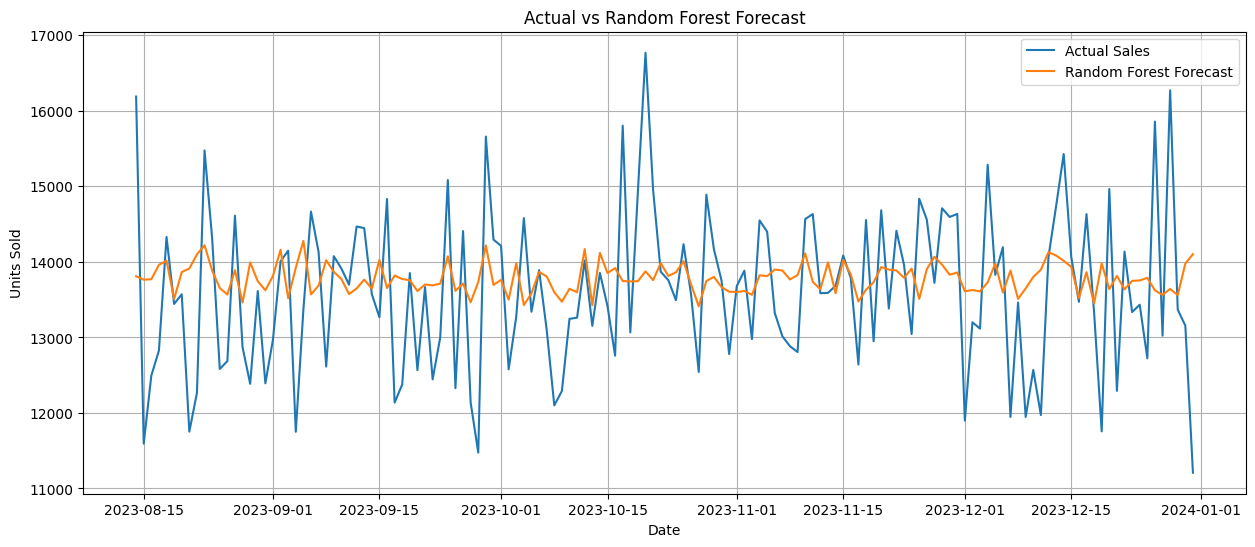

In [ ]:
# Visualize Random Forest predictions

plt.figure(figsize=(15, 6))

plt.plot(
    ml_data["Date"].iloc[split_index:],
    y_test.values,
    label="Actual Sales"
)

plt.plot(
    ml_data["Date"].iloc[split_index:],
    rf_forecast,
    label="Random Forest Forecast"
)

plt.title("Actual vs Random Forest Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)

plt.show()

The model is currently good at estimating the general demand level, but not as good at predicting sudden demand spikes or sharp drops.

That's particularly important for inventory planning because missing a demand spike can potentially lead to understocking.

So rather than immediately tuning Random Forest, let's answer an important question:

Which features is the Random Forest actually using most?

That gives us a meaningful business/ML analysis

In [ ]:
# Analyze Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print(feature_importance)

               Feature  Importance
0               Lag_28    0.096820
1      Rolling_30_Mean    0.091900
2            TimeIndex    0.090299
3                Lag_7    0.089920
4               Lag_14    0.085394
5       Rolling_7_Mean    0.084402
6                Lag_1    0.083974
7             Discount    0.083802
8   Competitor Pricing    0.076360
9                Price    0.071448
10     Rolling_14_Mean    0.066216
11       DayOfWeek_Num    0.033482
12               Month    0.032806
13             Quarter    0.006911
14           IsWeekend    0.006267
15   Holiday/Promotion    0.000000


Holiday/Promotion received zero impurity-based importance in this Random Forest model, indicating that it did not contribute to the tree splits used by this fitted model.

In [ ]:
# Permutation Importance

from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean
})

permutation_importance_df = permutation_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print(permutation_importance_df)

               Feature    Importance
0       Rolling_7_Mean  1.921954e+01
1               Lag_28  1.466142e+01
2      Rolling_30_Mean  5.698093e+00
3                Lag_1  3.373683e+00
4        DayOfWeek_Num  2.932408e+00
5            IsWeekend  1.545914e+00
6                Lag_7  1.456131e+00
7                Month  4.474735e-01
8    Holiday/Promotion -7.958079e-14
9            TimeIndex -1.136868e-13
10             Quarter -3.019029e-01
11  Competitor Pricing -1.312046e+00
12     Rolling_14_Mean -1.365722e+00
13              Lag_14 -1.659601e+00
14            Discount -3.129049e+00
15               Price -4.000355e+00


**permutation importance tells us**

We shuffle one feature at a time and see how much the model's MAE gets worse.

So:

Large positive importance → feature was useful.

Near zero → shuffling it made almost no difference.

Negative importance → after shuffling, performance actually improved slightly. This does not mean the feature has a "negative effect" on sales.


The standout is Rolling_7_Mean.

That makes intuitive sense:

The average sales of the previous 7 days gives the model a strong estimate of the current demand level.

And notice something important: this feature was calculated using .shift(1), so it does not contain today's actual sales.

"Permutation importance showed that recent historical demand, particularly the 7-day rolling average and 28-day lag, contributed most strongly to Random Forest forecasting performance. Calendar variables such as day of week also provided useful information, while pricing and competitor-related variables provided limited incremental predictive value in this fitted model."

**Our Random Forest achieved:**

MAE = 838.44

But the plot showed that it still misses the large peaks and drops.

So instead of spending time blindly tuning hundreds of Random Forest parameters, I'd like to test a gradient-boosting model next.

We'll use HistGradientBoostingRegressor from scikit-learn.


Why this model?

Random Forest builds many trees independently and averages them.

Gradient Boosting builds trees sequentially, with later trees trying to correct errors made by earlier trees.



In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


the parameters mean

max_iter=300

Maximum number of boosting iterations/trees.

learning_rate=0.05

Controls how much each new tree contributes. A smaller value generally gives the model a more gradual learning process.

max_leaf_nodes=15

Controls tree complexity. We're keeping the individual trees relatively controlled.

l2_regularization=1.0

Adds regularization to help reduce overfitting.


random_state=42

Makes the experiment reproducible.

In [ ]:
# Generate Gradient Boosting forecasts

gb_forecast = gb_model.predict(X_test)

print("Number of predictions:", len(gb_forecast))

print("\nFirst 10 predictions:")
print(gb_forecast[:10])

Number of predictions: 140

First 10 predictions:
[14124.23669531 14129.38362186 13778.28776775 14737.16364965
 13930.67171924 13991.20679947 13899.52189476 14447.27293953
 14279.87913482 13823.17361746]


In [ ]:
# Evaluate Gradient Boosting

mae_gb = mean_absolute_error(y_test, gb_forecast)

rmse_gb = np.sqrt(
    mean_squared_error(y_test, gb_forecast)
)

print("Gradient Boosting MAE :", mae_gb)
print("Gradient Boosting RMSE:", rmse_gb)

Gradient Boosting MAE : 910.407614838094
Gradient Boosting RMSE: 1166.4974843274313


“The feature-based Gradient Boosting model improved upon the naive baseline but performed worse than Random Forest on both MAE and RMSE. This suggests that the current Gradient Boosting configuration did not exploit the engineered lag and rolling features as effectively as the Random Forest model.”

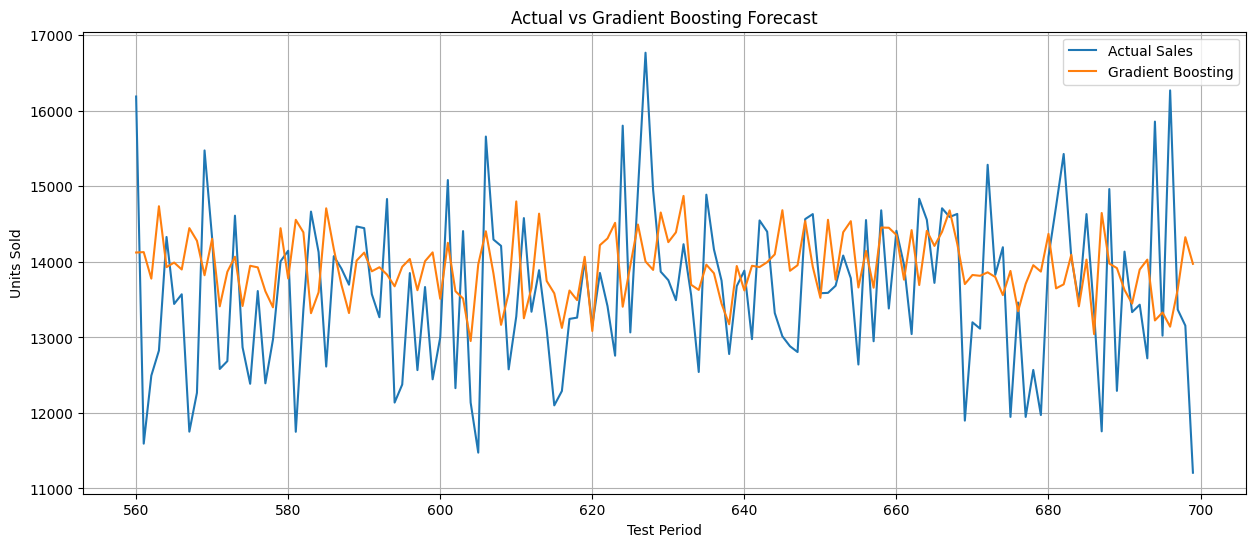

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Sales"
)

plt.plot(
    y_test.index,
    gb_forecast,
    label="Gradient Boosting"
)

plt.title("Actual vs Gradient Boosting Forecast")
plt.xlabel("Test Period")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)

plt.show()

“Gradient Boosting captured the overall demand level but tended to smooth extreme daily fluctuations, underpredicting high-demand peaks and overpredicting low-demand periods. This behavior contributed to its higher MAE and RMSE compared with the Random Forest model on the current evaluation window.”

In [ ]:
# Chronological Train / Validation / Test Split

n = len(ml_data)

train_end = int(n * 0.60)
validation_end = int(n * 0.80)

X_train_final = X.iloc[:train_end].copy()
X_validation = X.iloc[train_end:validation_end].copy()
X_test_final = X.iloc[validation_end:].copy()

y_train_final = y.iloc[:train_end].copy()
y_validation = y.iloc[train_end:validation_end].copy()
y_test_final = y.iloc[validation_end:].copy()

print("Training set :", X_train_final.shape)
print("Validation set:", X_validation.shape)
print("Final test set:", X_test_final.shape)

print("\nTraining period:")
print(ml_data["Date"].iloc[0], "to", ml_data["Date"].iloc[train_end - 1])

print("\nValidation period:")
print(ml_data["Date"].iloc[train_end], "to", ml_data["Date"].iloc[validation_end - 1])

print("\nFinal test period:")
print(ml_data["Date"].iloc[validation_end], "to", ml_data["Date"].iloc[-1])

Training set : (420, 16)
Validation set: (140, 16)
Final test set: (140, 16)

Training period:
2022-01-31 00:00:00 to 2023-03-26 00:00:00

Validation period:
2023-03-27 00:00:00 to 2023-08-13 00:00:00

Final test period:
2023-08-14 00:00:00 to 2023-12-31 00:00:00


Now we'll use:

Training -- choose model/configuration using validation -- retrain chosen model -- evaluate once on final test.

In [ ]:
# Validation with Random Forest
# Since Random Forest performed well previously, let's first see how it performs on the new validation period.
# We'll train it only on the training set.

from sklearn.ensemble import RandomForestRegressor

rf_validation_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(
    X_train_final,
    y_train_final
)

rf_validation_forecast = rf_validation_model.predict(
    X_validation
)

mae_rf_validation = mean_absolute_error(
    y_validation,
    rf_validation_forecast
)

rmse_rf_validation = np.sqrt(
    mean_squared_error(
        y_validation,
        rf_validation_forecast
    )
)

print("Random Forest Validation MAE :", mae_rf_validation)
print("Random Forest Validation RMSE:", rmse_rf_validation)

Random Forest Validation MAE : 939.5569557348108
Random Forest Validation RMSE: 1196.5430625659478


Random Forest — Validation performance

- MAE: 939.56

- RMSE: 1,196.54

What does it mean?

The model was trained on:

Jan 31, 2022 → Mar 26, 2023

and evaluated on completely later data:

Mar 27 → Aug 13, 2023

So this is a genuine future-style validation.



Next: Gradient Boosting validation

We need to evaluate Gradient Boosting on the exact same validation period.

In [ ]:

from sklearn.ensemble import HistGradientBoostingRegressor

gb_validation_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gb_validation_model.fit(
    X_train_final,
    y_train_final
)

gb_validation_forecast = gb_validation_model.predict(
    X_validation
)

mae_gb_validation = mean_absolute_error(
    y_validation,
    gb_validation_forecast
)

rmse_gb_validation = np.sqrt(
    mean_squared_error(
        y_validation,
        gb_validation_forecast
    )
)

print("Gradient Boosting Validation MAE :", mae_gb_validation)
print("Gradient Boosting Validation RMSE:", rmse_gb_validation)

Gradient Boosting Validation MAE : 998.1313660575289
Gradient Boosting Validation RMSE: 1265.8586270151482


"On the validation period from March 27 to August 13, 2023, the configured Random Forest model produced lower MAE and RMSE than the configured Gradient Boosting model."

In [ ]:
# Let's test a small set of Random Forest depths rather than doing a huge hyperparameter search.
rf_depths = [5, 10, 15, None]

rf_validation_results = []

for depth in rf_depths:

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_final, y_train_final)

    forecast = model.predict(X_validation)

    mae = mean_absolute_error(
        y_validation,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            forecast
        )
    )

    rf_validation_results.append({
        "Max Depth": depth,
        "MAE": mae,
        "RMSE": rmse
    })

rf_validation_results_df = pd.DataFrame(
    rf_validation_results
)

print(rf_validation_results_df)

   Max Depth         MAE         RMSE
0        5.0  911.731610  1156.545658
1       10.0  939.556956  1196.543063
2       15.0  940.397179  1196.243731
3        NaN  943.694167  1197.611561


The best validation performance among these configurations is max_depth=5, because it has the lowest MAE and RMSE.

Random Forest validation error by tree depth

Lower values indicate lower forecasting error on the validation period.



In [ ]:
# Before final testing, I'd like to check whether 300 trees are necessary.(This is another hyperparameter experiment, and the final test remains untouched.)


rf_estimators = [100, 300, 500]

rf_estimator_results = []

for n_trees in rf_estimators:

    model = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_final,
        y_train_final
    )

    forecast = model.predict(X_validation)

    mae = mean_absolute_error(
        y_validation,
        forecast
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation,
            forecast
        )
    )

    rf_estimator_results.append({
        "N Estimators": n_trees,
        "MAE": mae,
        "RMSE": rmse
    })

rf_estimator_results_df = pd.DataFrame(
    rf_estimator_results
)

print(rf_estimator_results_df)


   N Estimators         MAE         RMSE
0           100  920.235028  1160.661029
1           300  911.731610  1156.545658
2           500  908.746780  1151.026900


n_estimators means how many decision trees the Random Forest contains.

More trees generally make the forest's predictions more stable, although they also increase computation time.

 n_estimators = 500

gave progressively lower validation errors.

need to retrain our selected model using:

Training + Validation data together

(We've already used the validation period to choose the configuration. Now that we've made that decision, we can give the final model access to both datasets before asking it to forecast the completely unseen final test period.)

In [ ]:
# Combine Training and Validation Data

X_train_full = pd.concat(
    [X_train_final, X_validation]
)

y_train_full = pd.concat(
    [y_train_final, y_validation]
)

print("Full training set:", X_train_full.shape)
print("Full target set  :", y_train_full.shape)

print("\nTraining period:")
print(
    ml_data["Date"].iloc[0],
    "to",
    ml_data["Date"].iloc[validation_end - 1]
)

print("\nFinal test period:")
print(
    ml_data["Date"].iloc[validation_end],
    "to",
    ml_data["Date"].iloc[-1]
)

Full training set: (560, 16)
Full target set  : (560,)

Training period:
2022-01-31 00:00:00 to 2023-08-13 00:00:00

Final test period:
2023-08-14 00:00:00 to 2023-12-31 00:00:00


In [ ]:
# Train the Final Random Forest Model

final_rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_train_full,
    y_train_full
)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


In [ ]:
# Final Test Predictions

final_rf_forecast = final_rf_model.predict(
    X_test_final
)

final_mae_rf = mean_absolute_error(
    y_test_final,
    final_rf_forecast
)

final_rmse_rf = np.sqrt(
    mean_squared_error(
        y_test_final,
        final_rf_forecast
    )
)

print("Final Random Forest MAE :", final_mae_rf)
print("Final Random Forest RMSE:", final_rmse_rf)

Final Random Forest MAE : 834.9866134926476
Final Random Forest RMSE: 1056.5320194309631


In [ ]:
# Let's continue with the fair final model comparison.
# Align ARIMA and Prophet forecasts
# to the same final test period as Random Forest

common_test_dates = X_test_final.index

# Get the actual dates from ml_data
common_test_dates_actual = ml_data.loc[
    common_test_dates, "Date"
]

# ARIMA forecast aligned to Aug 14 -> Dec 31
arima_common_forecast = arima_100_forecast[
    arima_100_forecast.index.isin(common_test_dates_actual)
]

# Prophet forecast aligned to Aug 14 -> Dec 31
prophet_common = prophet_forecast[
    prophet_forecast["ds"].isin(common_test_dates_actual)
]

prophet_common_forecast = prophet_common["yhat"].values

print("Common test observations:", len(y_test_final))
print("ARIMA predictions:", len(arima_common_forecast))
print("Prophet predictions:", len(prophet_common_forecast))

print("\nCommon test period:")
print(common_test_dates_actual.min(), "to", common_test_dates_actual.max())

Common test observations: 140
ARIMA predictions: 140
Prophet predictions: 140

Common test period:
2023-08-14 00:00:00 to 2023-12-31 00:00:00


In [ ]:
# Now all three models will be evaluated against exactly the same 140 actual observations:

# Fair comparison on the common final test period

mae_arima_common = mean_absolute_error(
    y_test_final,
    arima_common_forecast.values
)

rmse_arima_common = np.sqrt(
    mean_squared_error(
        y_test_final,
        arima_common_forecast.values
    )
)

mae_prophet_common = mean_absolute_error(
    y_test_final,
    prophet_common_forecast
)

rmse_prophet_common = np.sqrt(
    mean_squared_error(
        y_test_final,
        prophet_common_forecast
    )

)

print("ARIMA(1,0,0)")
print("MAE :", mae_arima_common)
print("RMSE:", rmse_arima_common)

print("\nProphet")
print("MAE :", mae_prophet_common)
print("RMSE:", rmse_prophet_common)

print("\nRandom Forest")
print("MAE :", final_mae_rf)
print("RMSE:", final_rmse_rf)

ARIMA(1,0,0)
MAE : 853.3630381628753
RMSE: 1061.535322514551

Prophet
MAE : 858.4090754444233
RMSE: 1074.9368100759268

Random Forest
MAE : 834.9866134926476
RMSE: 1056.5320194309631


**“The final Random Forest model achieved the lowest MAE and RMSE among the evaluated models on the common 140-day test period.”**

We need to answer an important question:

"Where does the Random Forest make its biggest forecasting errors?".

**Create an error-analysis DataFrame**

In [ ]:
# Analyze final model errors

error_analysis = pd.DataFrame({
    "Date": ml_data.loc[X_test_final.index, "Date"].values,
    "Actual": y_test_final.values,
    "Predicted": final_rf_forecast
})

error_analysis["Error"] = (
    error_analysis["Actual"]
    - error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

error_analysis["Percentage_Error"] = (
    error_analysis["Absolute_Error"]
    / error_analysis["Actual"].replace(0, np.nan)
) * 100

print(error_analysis.head())

print("\nShape:", error_analysis.shape)

print("\nLargest absolute errors:")
print(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

        Date  Actual     Predicted        Error  Absolute_Error  \
0 2023-08-14   16190  13689.384010  2500.615990     2500.615990   
1 2023-08-15   11593  13684.949083 -2091.949083     2091.949083   
2 2023-08-16   12494  13709.803662 -1215.803662     1215.803662   
3 2023-08-17   12826  13868.476833 -1042.476833     1042.476833   
4 2023-08-18   14330  13988.614003   341.385997      341.385997   

   Percentage_Error  
0         15.445435  
1         18.044933  
2          9.731100  
3          8.127841  
4          2.382317  

Shape: (140, 6)

Largest absolute errors:
          Date  Actual     Predicted        Error  Absolute_Error  \
67  2023-10-20   16770  13776.504193  2993.495807     2993.495807   
139 2023-12-31   11208  13891.822805 -2683.822805     2683.822805   
136 2023-12-28   16271  13605.511891  2665.488109     2665.488109   
0   2023-08-14   16190  13689.384010  2500.615990     2500.615990   
45  2023-09-28   11474  13717.389676 -2243.389676     2243.389676   
134 2023

Error = Actual − Predicted

So:

- Positive Error → model underpredicted demand.

- Negative Error → model overpredicted demand.

- Absolute Error → size of the mistake, regardless of direction.

For example:

2023-08-14

- Actual = 16,190

- Predicted = 13,689

- Error = +2,501

- → The model underestimated demand by about 2,501 units.

2023-08-15

- Actual = 11,593
- Predicted = 13,685
- Error = −2,092
- → The model overestimated demand by about 2,092 units.

**There is a clear pattern:**

Random Forest tends to predict around the middle of the historical demand range.

When actual demand suddenly becomes:

📈 very high → it tends to underestimate.


When actual demand suddenly becomes:

📉 very low → it tends to overestimate.


This is called regression toward the mean / prediction smoothing.
That also explains why earlier plot showed the Random Forest following the general level but missing sharp peaks and drops.

model has historical features such as:
- Lag_1
- Lag_7
- Lag_14
- Lag_28
- rolling averages
- calendar features
- price
- discount
- competitor pricing
- promotion

These are useful, but they don't completely explain unexpected daily demand shocks.

The model doesn't have enough information to confidently predict that large spike, so it stays closer to the normal level.

percentage errors tell the same story:

largest errors have approximately:
- 14-24% percentage error
- Dec 31 - 23.95%
- Sep 28 - 19.55%
- Aug 15 - 18.04%
- Oct 20 - 17.85%

So the model's biggest mistakes occur during unusual high/low demand days.

**"Error Analysis: The Random Forest model performed reasonably well on typical demand days but showed larger errors during extreme demand fluctuations. High-demand peaks were generally underestimated, while low-demand periods were overestimated, indicating that the model tends to smooth short-term demand volatility."**

**Now we should investigate why those large errors happened.**

For example:
Oct 20, 2023 → actual = 16,770

Was there:
- a promotion?
- a large discount?
- unusual weather?
- unusually high previous-day sales?
- a particular day of the week?

**We can connect the errors back to business variables.**

In [ ]:
error_analysis_with_features = error_analysis.merge(
    df_clean[
        [
            "Date",
            "Price",
            "Discount",
            "Weather Condition",
            "Holiday/Promotion"
        ]
    ],
    on="Date",
    how="left"
).drop_duplicates("Date")

print(
    error_analysis_with_features
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

            Date  Actual     Predicted        Error  Absolute_Error  \
6700  2023-10-20   16770  13776.504193  2993.495807     2993.495807   
13900 2023-12-31   11208  13891.822805 -2683.822805     2683.822805   
13600 2023-12-28   16271  13605.511891  2665.488109     2665.488109   
0     2023-08-14   16190  13689.384010  2500.615990     2500.615990   
4500  2023-09-28   11474  13717.389676 -2243.389676     2243.389676   
13400 2023-12-26   15858  13626.168874  2231.831126     2231.831126   
6400  2023-10-17   15804  13698.653078  2105.346922     2105.346922   
12700 2023-12-19   11756  13853.573046 -2097.573046     2097.573046   
100   2023-08-15   11593  13684.949083 -2091.949083     2091.949083   
700   2023-08-21   11752  13828.696573 -2076.696573     2076.696573   

       Percentage_Error  Price  Discount Weather Condition  Holiday/Promotion  
6700          17.850303  84.57        10            Cloudy                  0  
13900         23.945600  96.19         0             Rainy

A particularly interesting finding:

Notice that both very high and very low demand occurred under different combinations of:

- discount
- promotion
- weather
- price

That supports our earlier conclusion:

**The biggest challenge for the model is sudden demand volatility rather than one obvious business variable.**

In [ ]:
# let's aggregate the business variables properly at the daily level, just like we did when building the ML features.

daily_error_context = (
    df_clean
    .groupby("Date")
    .agg({
        "Price": "mean",
        "Discount": "mean",
        "Competitor Pricing": "mean",
        "Holiday/Promotion": "max",
        "Weather Condition": lambda x: x.mode()[0]
    })
    .reset_index()
)

error_analysis_context = error_analysis.merge(
    daily_error_context,
    on="Date",
    how="left"
)

print(
    error_analysis_context
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

          Date  Actual     Predicted        Error  Absolute_Error  \
67  2023-10-20   16770  13776.504193  2993.495807     2993.495807   
139 2023-12-31   11208  13891.822805 -2683.822805     2683.822805   
136 2023-12-28   16271  13605.511891  2665.488109     2665.488109   
0   2023-08-14   16190  13689.384010  2500.615990     2500.615990   
45  2023-09-28   11474  13717.389676 -2243.389676     2243.389676   
134 2023-12-26   15858  13626.168874  2231.831126     2231.831126   
64  2023-10-17   15804  13698.653078  2105.346922     2105.346922   
127 2023-12-19   11756  13853.573046 -2097.573046     2097.573046   
1   2023-08-15   11593  13684.949083 -2091.949083     2091.949083   
7   2023-08-21   11752  13828.696573 -2076.696573     2076.696573   

     Percentage_Error    Price  Discount  Competitor Pricing  \
67          17.850303  58.7589      9.40             58.4916   
139         23.945600  59.2518      8.70             59.5656   
136         16.381833  58.3097     10.00        

"Many of the largest prediction errors occurred on promotion days, suggesting that promotional periods may be associated with demand patterns that the current model does not fully capture. Further analysis is required to determine the strength of this relationship."

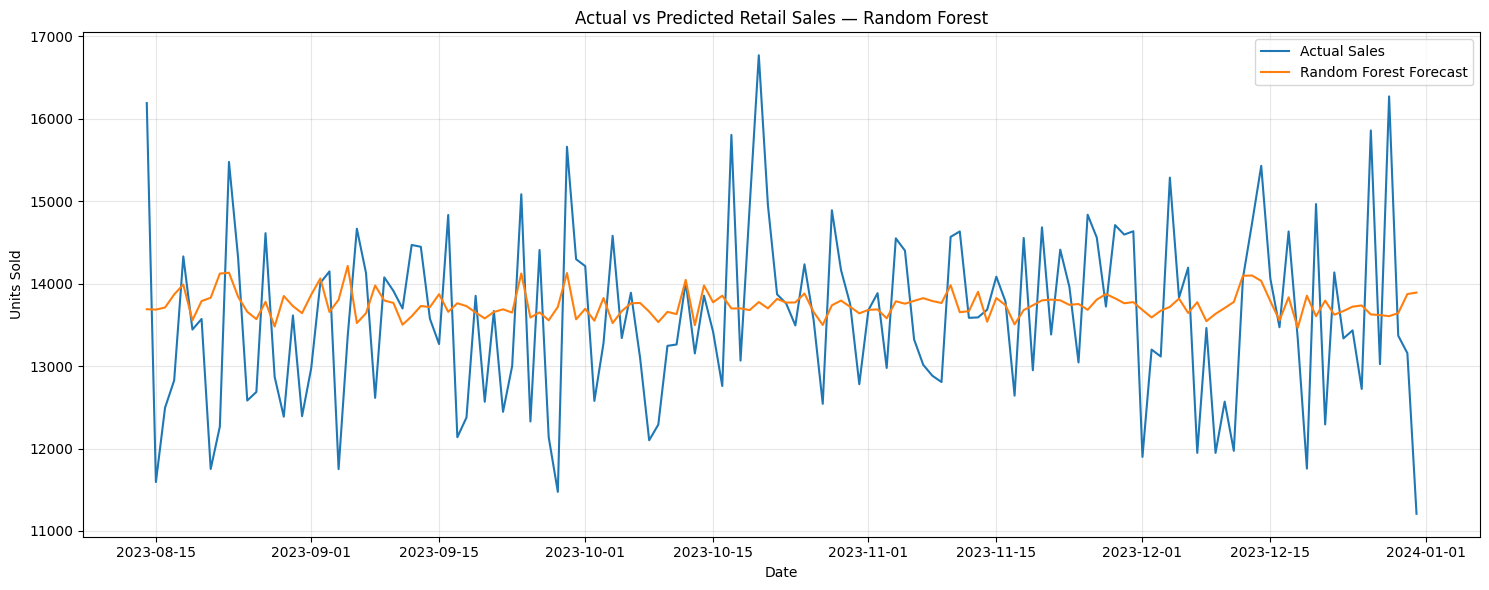

In [ ]:
# Visualize the final model:
# Actual vs Predicted — Final Random Forest (This will visually demonstrate how model performs across the entire 140-day test period.)


plt.figure(figsize=(15, 6))

plt.plot(
    error_analysis["Date"],
    error_analysis["Actual"],
    label="Actual Sales"
)

plt.plot(
    error_analysis["Date"],
    error_analysis["Predicted"],
    label="Random Forest Forecast"
)

plt.title("Actual vs Predicted Retail Sales — Random Forest")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Model Behavior: The Random Forest model successfully captured the overall level of daily retail demand but produced smoother predictions than the actual sales series. It tended to underestimate high-demand peaks and overestimate sudden demand drops, indicating that short-term demand volatility remains challenging to predict using the current feature set.**

# Future Demand Forecasting:

Random Forest uses features such as:

- Lag_1
- Lag_7
- Lag_14
- Lag_28
- Rolling_7_Mean
- Rolling_14_Mean
- Rolling_30_Mean

For a future date, we don't know the future Units Sold yet.

So we cannot simply create future rows and fill these lag features with actual future sales.

That would be data leakage.

**Instead, we'll use recursive forecasting:**

Day 1 forecast → use that forecast to construct Day 2 features → forecast Day 2 → continue forward.

**Define the future forecast horizon**:

Our modeling data ends at December 31, 2023. The dataset has January 1, 2024, but that date is only partially represented, so we should not use it as a normal historical day.

let's create a 30-day future demand forecast starting January 1, 2024.

This will demonstrate how model can be used for future planning.

Why 30 days?

A 30-day horizon is a good demonstration for inventory and demand planning without pretending that we can reliably predict an arbitrarily long period.

In [ ]:
forecast_start = pd.Timestamp("2024-01-01")
forecast_days = 30

future_dates = pd.date_range(
    start=forecast_start,
    periods=forecast_days,
    freq="D"
)

print("Forecast period:")
print(future_dates.min(), "to", future_dates.max())

print("\nNumber of forecast days:", len(future_dates))

Forecast period:
2024-01-01 00:00:00 to 2024-01-30 00:00:00

Number of forecast days: 30


**Create a realistic baseline scenario**: (not a claim about what the actual January 2024 business conditions were.")

For our first future forecast, we'll use a baseline business scenario:

- Price: average of the most recent 30 complete days

- Discount: average of the most recent 30 complete days

- Competitor Pricing: average of the most recent 30 complete days

- Holiday/Promotion: assume 0 (no promotion)

Why no promotion? Because we don't want to invent future promotional events. Later, we can create a promotion scenario and show how demand changes.

In [ ]:
recent_30_days = daily_business[
    daily_business["Date"] <= pd.Timestamp("2023-12-31")
].tail(30)

future_business_assumptions = {
    "Price": recent_30_days["Price"].mean(),
    "Discount": recent_30_days["Discount"].mean(),
    "Competitor Pricing": recent_30_days["Competitor Pricing"].mean(),
    "Holiday/Promotion": 0
}

print("Future business assumptions:")
for feature, value in future_business_assumptions.items():
    print(f"{feature}: {value:.2f}" if feature != "Holiday/Promotion"
          else f"{feature}: {value}")

Future business assumptions:
Price: 55.03
Discount: 10.03
Competitor Pricing: 54.95
Holiday/Promotion: 0


These are based on the recent 30-day averages, except promotion, which we deliberately set to 0 rather than inventing future promotions.

**Build the future feature table:**

Now we'll create the 30 future dates and populate the known future features.

At this stage, we will not calculate the lag/rolling features yet. Those require recursive forecasting.


In [ ]:
future_data = pd.DataFrame({
    "Date": future_dates
})

future_data["DayOfWeek_Num"] = future_data["Date"].dt.dayofweek
future_data["IsWeekend"] = (
    future_data["DayOfWeek_Num"] >= 5
).astype(int)

future_data["Month"] = future_data["Date"].dt.month
future_data["Quarter"] = future_data["Date"].dt.quarter

future_data["Price"] = future_business_assumptions["Price"]
future_data["Discount"] = future_business_assumptions["Discount"]
future_data["Competitor Pricing"] = (
    future_business_assumptions["Competitor Pricing"]
)
future_data["Holiday/Promotion"] = (
    future_business_assumptions["Holiday/Promotion"]
)

future_data["TimeIndex"] = np.arange(
    ml_data["TimeIndex"].max() + 1,
    ml_data["TimeIndex"].max() + 1 + forecast_days
)

print(future_data[["Date", "TimeIndex"]].head())
print("\nLast rows:")
print(future_data[["Date", "TimeIndex"]].tail())

print(future_data.head())
print("\nShape:", future_data.shape)

        Date  TimeIndex
0 2024-01-01        730
1 2024-01-02        731
2 2024-01-03        732
3 2024-01-04        733
4 2024-01-05        734

Last rows:
         Date  TimeIndex
25 2024-01-26        755
26 2024-01-27        756
27 2024-01-28        757
28 2024-01-29        758
29 2024-01-30        759
        Date  DayOfWeek_Num  IsWeekend  Month  Quarter     Price   Discount  \
0 2024-01-01              0          0      1        1  55.03425  10.028333   
1 2024-01-02              1          0      1        1  55.03425  10.028333   
2 2024-01-03              2          0      1        1  55.03425  10.028333   
3 2024-01-04              3          0      1        1  55.03425  10.028333   
4 2024-01-05              4          0      1        1  55.03425  10.028333   

   Competitor Pricing  Holiday/Promotion  TimeIndex  
0            54.94678                  0        730  
1            54.94678                  0        731  
2            54.94678                  0        732  
3  

**Prepare historical sales:**

Our Random Forest needs Lag_1, Lag_7, Lag_14, Lag_28, and rolling averages. For January 1, these must come from the last known sales values through December 31, 2023.

In [ ]:
history_sales = (
    daily_sales_model
    .set_index("Date")["Units Sold"]
    .copy()
)

print("Last known date:", history_sales.index.max())
print("Number of historical days:", len(history_sales))

print("\nLast 7 days of sales:")
print(history_sales.tail(7))

Last known date: 2023-12-31 00:00:00
Number of historical days: 730

Last 7 days of sales:
Date
2023-12-25    12723
2023-12-26    15858
2023-12-27    13023
2023-12-28    16271
2023-12-29    13368
2023-12-30    13156
2023-12-31    11208
Name: Units Sold, dtype: int64


In [ ]:
# Build the recursive forecast:

future_forecasts = []

for i in range(forecast_days):

    current_date = future_data.loc[i, "Date"]

    # Historical/previously predicted sales
    lag_1 = history_sales.iloc[-1]
    lag_7 = history_sales.iloc[-7]
    lag_14 = history_sales.iloc[-14]
    lag_28 = history_sales.iloc[-28]

    rolling_7 = history_sales.iloc[-7:].mean()
    rolling_14 = history_sales.iloc[-14:].mean()
    rolling_30 = history_sales.iloc[-30:].mean()

    # Build feature row
    feature_row = pd.DataFrame([{
        "Lag_1": lag_1,
        "Lag_7": lag_7,
        "Lag_14": lag_14,
        "Lag_28": lag_28,
        "Rolling_7_Mean": rolling_7,
        "Rolling_14_Mean": rolling_14,
        "Rolling_30_Mean": rolling_30,
        "DayOfWeek_Num": future_data.loc[i, "DayOfWeek_Num"],
        "IsWeekend": future_data.loc[i, "IsWeekend"],
        "Month": future_data.loc[i, "Month"],
        "Quarter": future_data.loc[i, "Quarter"],
        "Price": future_data.loc[i, "Price"],
        "Discount": future_data.loc[i, "Discount"],
        "Competitor Pricing": future_data.loc[i, "Competitor Pricing"],
        "Holiday/Promotion": future_data.loc[i, "Holiday/Promotion"],
        "TimeIndex": future_data.loc[i, "TimeIndex"]
    }])

    # Make prediction
    prediction = final_rf_model.predict(
        feature_row[feature_columns]
    )[0]

    # Store prediction
    future_forecasts.append(prediction)

    # Add prediction to history so it can be used for the next day
    history_sales.loc[current_date] = prediction

print("Forecast completed.")
print("Number of predictions:", len(future_forecasts))

Forecast completed.
Number of predictions: 30


What this code is doing

For Jan 1, it uses actual historical sales:

Dec 31 → Lag 1
Dec 25 → Lag 7
Dec 18 → Lag 14
Dec 4  → Lag 28

Then Random Forest predicts Jan 1.

For Jan 2, something important happens:

Jan 1 prediction -- becomes part of the history
                         --
                    predict Jan 2

And this continues until Jan 30.

**This is called recursive forecasting.**

In [ ]:
# Create the final forecast table:

future_forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecasted_Units_Sold": future_forecasts
})

print(future_forecast_df.head(10))

print("\nShape:", future_forecast_df.shape)

print("\nForecast summary:")
print(future_forecast_df["Forecasted_Units_Sold"].describe())

        Date  Forecasted_Units_Sold
0 2024-01-01           13598.203514
1 2024-01-02           13621.157409
2 2024-01-03           13733.096771
3 2024-01-04           13652.280962
4 2024-01-05           13722.361503
5 2024-01-06           13632.737411
6 2024-01-07           13717.594424
7 2024-01-08           13603.219839
8 2024-01-09           13628.150808
9 2024-01-10           13690.856671

Shape: (30, 2)

Forecast summary:
count       30.000000
mean     13701.679588
std         83.848819
min      13509.357917
25%      13634.199058
50%      13728.246104
75%      13765.257181
max      13812.011140
Name: Forecasted_Units_Sold, dtype: float64


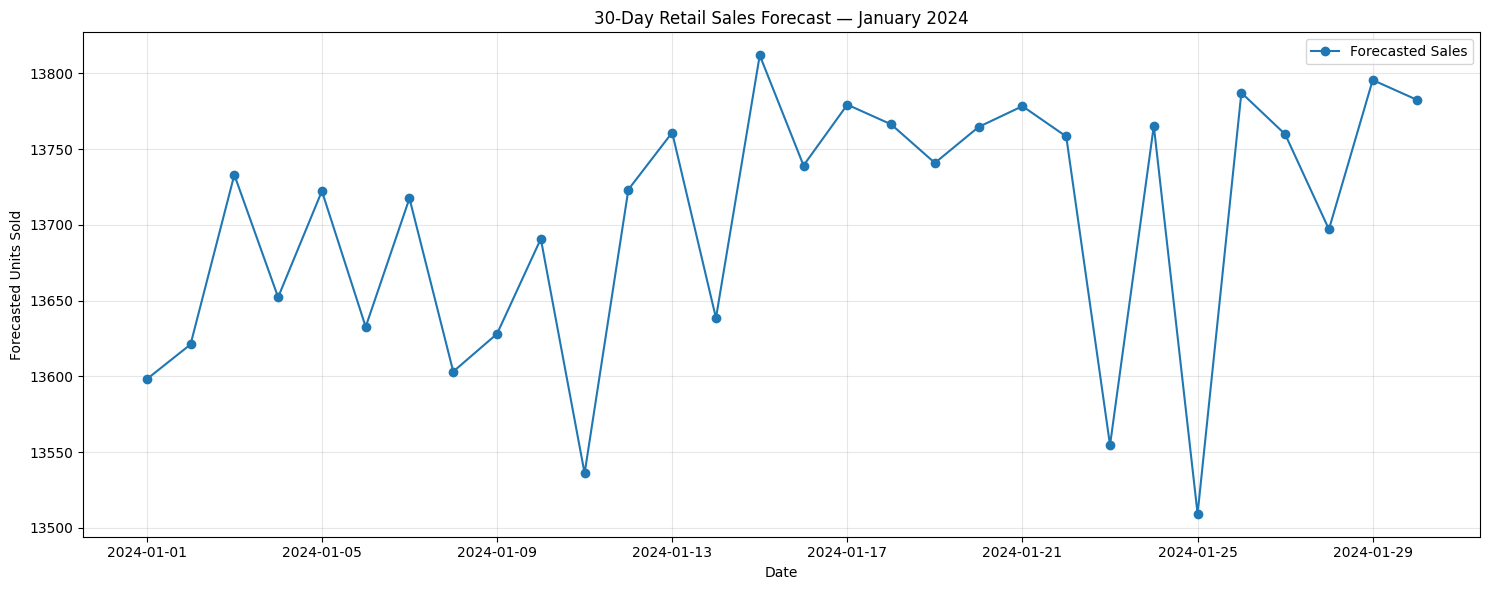

In [ ]:
# Visualize the 30-day forecast:

plt.figure(figsize=(15, 6))

plt.plot(
    future_forecast_df["Date"],
    future_forecast_df["Forecasted_Units_Sold"],
    marker="o",
    label="Forecasted Sales"
)

plt.title("30-Day Retail Sales Forecast — January 2024")
plt.xlabel("Date")
plt.ylabel("Forecasted Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**"30-Day Demand Forecast: The Random Forest model forecasts relatively stable daily retail demand during January 2024, averaging approximately 13,702 units per day. However, the narrow forecast range reflects the model's tendency to smooth extreme demand fluctuations observed historically. Therefore, the forecast should be used as a baseline for inventory planning rather than as an exact representation of daily demand."**

In [ ]:
# Calculate total January demand:
# Now let's turn the daily forecast into a business planning number.

total_forecast_demand = (
    future_forecast_df["Forecasted_Units_Sold"].sum()
)

average_daily_demand = (
    future_forecast_df["Forecasted_Units_Sold"].mean()
)

peak_forecast_demand = (
    future_forecast_df["Forecasted_Units_Sold"].max()
)

lowest_forecast_demand = (
    future_forecast_df["Forecasted_Units_Sold"].min()
)

print(f"Total forecasted demand: {total_forecast_demand:,.0f} units")
print(f"Average daily demand: {average_daily_demand:,.0f} units")
print(f"Peak forecasted demand: {peak_forecast_demand:,.0f} units")
print(f"Lowest forecasted demand: {lowest_forecast_demand:,.0f} units")

Total forecasted demand: 411,050 units
Average daily demand: 13,702 units
Peak forecasted demand: 13,812 units
Lowest forecasted demand: 13,509 units


Important business insight

We should not immediately say:

“The company should stock 411,050 units.”

That's not quite correct because inventory planning also needs to account for forecast uncertainty, lead time, and desired service level.

Demand forecast - forecast uncertainty - safety stock - reorder point.

In [ ]:
# Measure forecast uncertainty:

validation_errors = (
    y_validation.values - rf_validation_forecast
)

validation_error_std = np.std(
    validation_errors,
    ddof=1
)

validation_mae = mean_absolute_error(
    y_validation,
    rf_validation_forecast
)

print(f"Validation MAE: {validation_mae:,.2f} units")
print(f"Validation error standard deviation: {validation_error_std:,.2f} units")

Validation MAE: 939.56 units
Validation error standard deviation: 1,151.34 units


Validation MAE = 939.56 units

On the validation period, the model's typical absolute error was about 940 units/day.

Validation error standard deviation = 1,151.34 units

The errors had substantial variation, which is important for inventory planning.

This is another reason we shouldn't use the forecast alone to decide inventory levels.

For example, your January forecast says about 13,702 units/day, but actual demand can deviate considerably from that level.

**Inventory planning scenario:**

We'll use an illustrative scenario:

Lead time = 7 days
Service level = 95%
Z-score = 1.645

Meaning:

"If replenishment takes 7 days and the business targets a 95% service level, what inventory level would be appropriate under this forecasting scenario?"

we'll calculate safety stock and then reorder point.

In [ ]:
lead_time_days = 7
service_level_z = 1.645  # 95% service level

safety_stock = (
    service_level_z
    * validation_error_std
    * np.sqrt(lead_time_days)
)

reorder_point = (
    average_daily_demand * lead_time_days
    + safety_stock
)

print(f"Assumed lead time: {lead_time_days} days")
print(f"Assumed service level: 95%")
print(f"Safety stock: {safety_stock:,.0f} units")
print(f"Reorder point: {reorder_point:,.0f} units")

Assumed lead time: 7 days
Assumed service level: 95%
Safety stock: 5,011 units
Reorder point: 100,923 units


In [ ]:
# Create a final business summary:

business_summary = pd.DataFrame({
    "Metric": [
        "Forecast Horizon",
        "Total Forecasted Demand",
        "Average Daily Demand",
        "Peak Daily Forecast",
        "Lowest Daily Forecast",
        "Validation MAE",
        "Forecast Error Std",
        "Assumed Lead Time",
        "Assumed Service Level",
        "Safety Stock",
        "Reorder Point"
    ],
    "Value": [
        "30 days",
        f"{total_forecast_demand:,.0f} units",
        f"{average_daily_demand:,.0f} units/day",
        f"{peak_forecast_demand:,.0f} units/day",
        f"{lowest_forecast_demand:,.0f} units/day",
        f"{validation_mae:,.2f} units",
        f"{validation_error_std:,.2f} units",
        f"{lead_time_days} days",
        "95%",
        f"{safety_stock:,.0f} units",
        f"{reorder_point:,.0f} units"
    ]
})

business_summary

,Metric,Value
0,Forecast Horizon,30 days
1,Total Forecasted Demand,"411,050 units"
2,Average Daily Demand,"13,702 units/day"
3,Peak Daily Forecast,"13,812 units/day"
4,Lowest Daily Forecast,"13,509 units/day"
5,Validation MAE,939.56 units
6,Forecast Error Std,"1,151.34 units"
7,Assumed Lead Time,7 days
8,Assumed Service Level,95%
9,Safety Stock,"5,011 units"


## Final Model Performance Summary

In [ ]:
# Calculate relative improvement:

final_model_comparison = pd.DataFrame({
    "Model": [
        "ARIMA(1,0,0)",
        "Prophet",
        "Random Forest"
    ],
    "MAE": [
        853.3630381628753,
        858.4090754444233,
        834.9866134926475
    ],
    "RMSE": [
        1061.535322514551,
        1074.9368100759268,
        1056.5320194309631
    ]
})

rf_mae = final_model_comparison.loc[
    final_model_comparison["Model"] == "Random Forest",
    "MAE"
].iloc[0]

rf_rmse = final_model_comparison.loc[
    final_model_comparison["Model"] == "Random Forest",
    "RMSE"
].iloc[0]

final_model_comparison["MAE_Improvement_vs_RF_%"] = (
    (final_model_comparison["MAE"] - rf_mae)
    / final_model_comparison["MAE"]
) * 100

final_model_comparison["RMSE_Improvement_vs_RF_%"] = (
    (final_model_comparison["RMSE"] - rf_rmse)
    / final_model_comparison["RMSE"]
) * 100

final_model_comparison

,Model,MAE,RMSE,MAE_Improvement_vs_RF_%,RMSE_Improvement_vs_RF_%
0,"ARIMA(1,0,0)",853.363038,1061.535323,2.153412,0.471327
1,Prophet,858.409075,1074.936810,2.728590,1.712174
2,Random Forest,834.986613,1056.532019,0.000000,0.000000


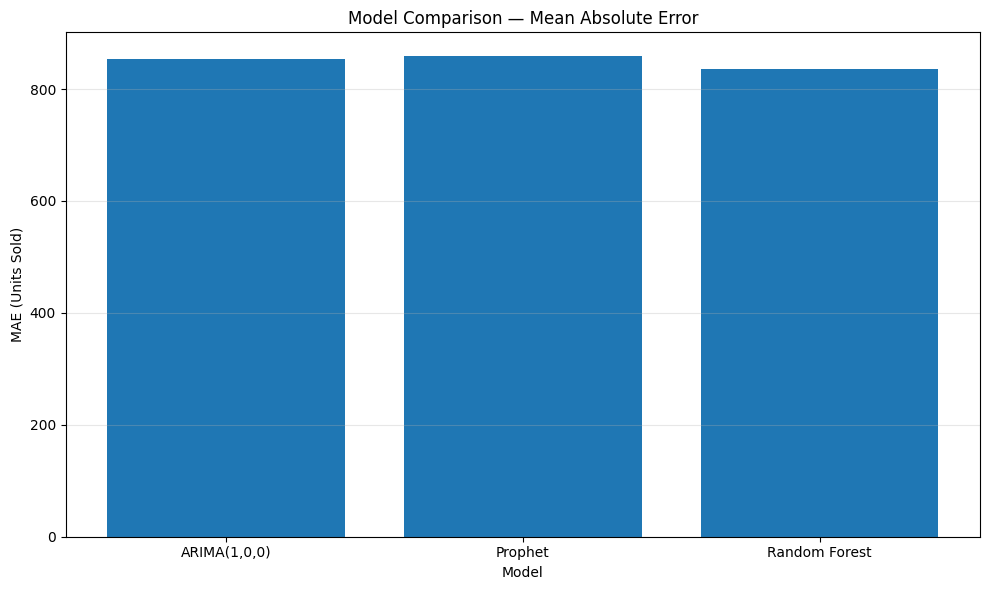

In [ ]:
# Model comparison chart:

plt.figure(figsize=(10, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAE"]
)

plt.title("Model Comparison — Mean Absolute Error")
plt.xlabel("Model")
plt.ylabel("MAE (Units Sold)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Model Comparison: Random Forest achieved the lowest MAE of 834.99 units on the final 140-day holdout period, compared with 853.36 for ARIMA and 858.41 for Prophet. The relatively small differences indicate that all three approaches achieved broadly similar forecasting accuracy, with Random Forest providing the lowest observed error on this test period.**



**Final Model Selection: Random Forest was selected as the final forecasting model because it achieved the lowest MAE and RMSE on the common final holdout period and was selected through validation-based hyperparameter tuning. **

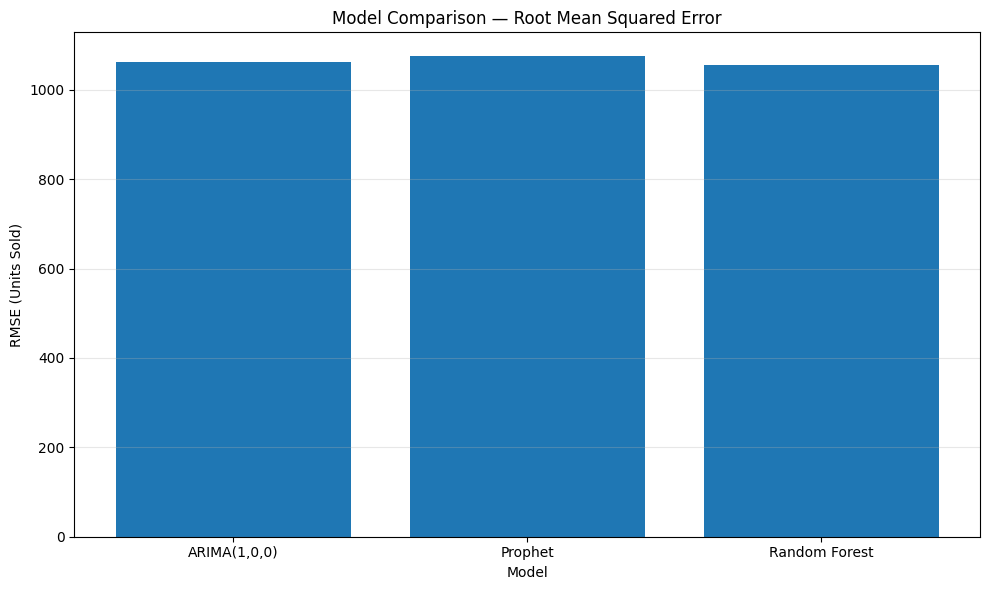

In [ ]:
#  Create the RMSE comparison chart:

plt.figure(figsize=(10, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["RMSE"]
)

plt.title("Model Comparison — Root Mean Squared Error")
plt.xlabel("Model")
plt.ylabel("RMSE (Units Sold)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Random Forest achieved the lowest observed forecasting error on the final holdout period, but the performance differences between the three models were relatively small.**

### Inventory Planning and Supply Chain Scheduling

The analysis connects demand forecasting to inventory planning through a transparent, historical January 2024 scenario. It forecasts approximately 411,050 units over 30 days and translates that demand into an estimated seven-day reorder point using an assumed 95% service level. This makes the link between forecast demand, uncertainty, and replenishment planning easy to interpret. The resulting safety stock is approximately 5,011 units, producing an aggregate reorder-point estimate of approximately 100,923 units.

These values are illustrative because demand is aggregated across all stores and products; they do not specify which items to order, when to order, or how much to order. The safety-stock estimate is also preliminary: it scales one-day validation-error variation to a seven-day lead time, using errors from a Random Forest configuration different from the selected final model. Supplier schedules, inventory position, open orders, review frequency, and order constraints are not incorporated, and the policy has not been evaluated for achieved service level, stockouts, or inventory cost. The results therefore demonstrate a clear forecasting-to-replenishment concept under stated assumptions, while an operational schedule would require store–product forecasts and validated supply and inventory information.

### Limitations and Next Steps

This analysis uses a synthetic dataset covering January 2022 through January 2024, so its patterns should be treated as a forecasting demonstration rather than evidence of real retail performance. The inventory scenario aggregates demand across 100 store–product combinations, and its seven-day lead time and 95% service level are assumptions. The resulting figures do not represent validated item-level reorder recommendations.

A practical next step is to forecast each store–product series and evaluate seven-day forecasts across multiple historical periods using only information available at each forecast date. Safety stock can then be estimated from the resulting lead-time forecast errors. With validated on-hand inventory, open orders, supplier lead times, and order constraints, a replenishment simulation could compare service level, stockout days, average inventory, and inventory cost. Until then, the results are best interpreted as an illustrative planning scenario.